In [67]:
# Timer for notebook
import time
_start_time = time.perf_counter()

# Put imports here
import numpy as np
from scipy import stats, special, integrate, fft
import matplotlib.pyplot as plt
import mp2lib as ml

SEED = 1320312820 # drawn 2026-10-29, do not change
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8, rng_A, rng_B = rng.spawn(10)

magnitude = 6
n = np.zeros(magnitude + 1, dtype=int)
for i in range(magnitude + 1):
    n[i] = 10 ** i

## Step 1
Work with four distributions: uniform on [0,1], exponential with rate 1, standard Gaussian, and Rayleigh with scale 1.

### 1. For each, write the CDF and the PDF in a Markdown cell, and state the support.

*Uniform [0,1]:*

PDF:
$$
f_X(x) =
\begin{cases}
    \frac{1}{b-a} & \text{if }\text{ } a \leq x \leq b
    \\ 0, & \text{else}
\end{cases}
$$

CDF:

$$
F_X(x) = P(X \leq x) =  
\begin{cases}
    0 & \text{if }\text{ } x < 0
    \\ x & \text{if }\text{ } 0 \leq x \leq 1 
    \\ 1 & \text{if }\text{ } x \geq 1
\end{cases}
$$

*Exponential with rate 1:*

PDF: 
$$
f_X(x) =
\begin{cases}
    e^{-x} & \text{if }\text{ } x \geq 0
    \\ 0 & \text{else }
\end{cases}
$$

CDF:

$$
F_X(x) = P(X \leq x) = 
\begin{cases}
    1 - e^{-x} & \text{if }\text{ } x \geq 0
    \\ 0 & \text{else }
\end{cases}
$$

*Standard Gaussian:*

PDF: 
$$
f_Z(z) = \frac{1}{\sqrt{2\pi}} e^{-z^2/2} \ \ \text{for } z \ \epsilon \ \mathbb{R}
\\ \text{where } z = \frac{x-\mu}{\sigma}
$$

CDF:

$$
\Phi(z) = \frac{1}{\sqrt{2\pi}} \int_{-\infty}^{z} e^{-u^2/2} \,du  \ \ \text{for } z \ \epsilon \ \mathbb{R}
\\ \text{where } z = \frac{x-\mu}{\sigma}
$$

*Rayleigh with scale 1:*

PDF: 
$$
f_X(x;\sigma=1) = x e^{-x^2/(2)} \ \ \text{for } x \geq 0
$$

CDF:

$$
F_X(x;\sigma=1) = 1 - e^{-x^2/(2)} \ \ \text{for } x \ \epsilon \ [0,\infty)
$$

### 2. Generate 10<sup>5</sup> samples of each with the library generators.

In [2]:
unif = rng_1.random(size=n[5])
expo = rng_1.exponential(scale=1.0, size=n[5])
gau = rng_1.standard_normal(size=n[5])
ray = rng_1.rayleigh(scale=1.0, size=n[5])

# print("Uniform [0,1]\t\t\tExponential w/ Rate 1\t\tStandard Gaus\t\t\tRayleigh scale 1")
# print("----------------------------------------------------------------------------------------------------------------------")
# for i in range(0, n, 1): 
#     print(unif[i], end="\t\t")
#     print(expo[i], end="\t\t")
#     print(gau[i], end="\t\t")
#     print(ray[i])

### 3. Plot the empirical CDF against the analytic CDF for each.

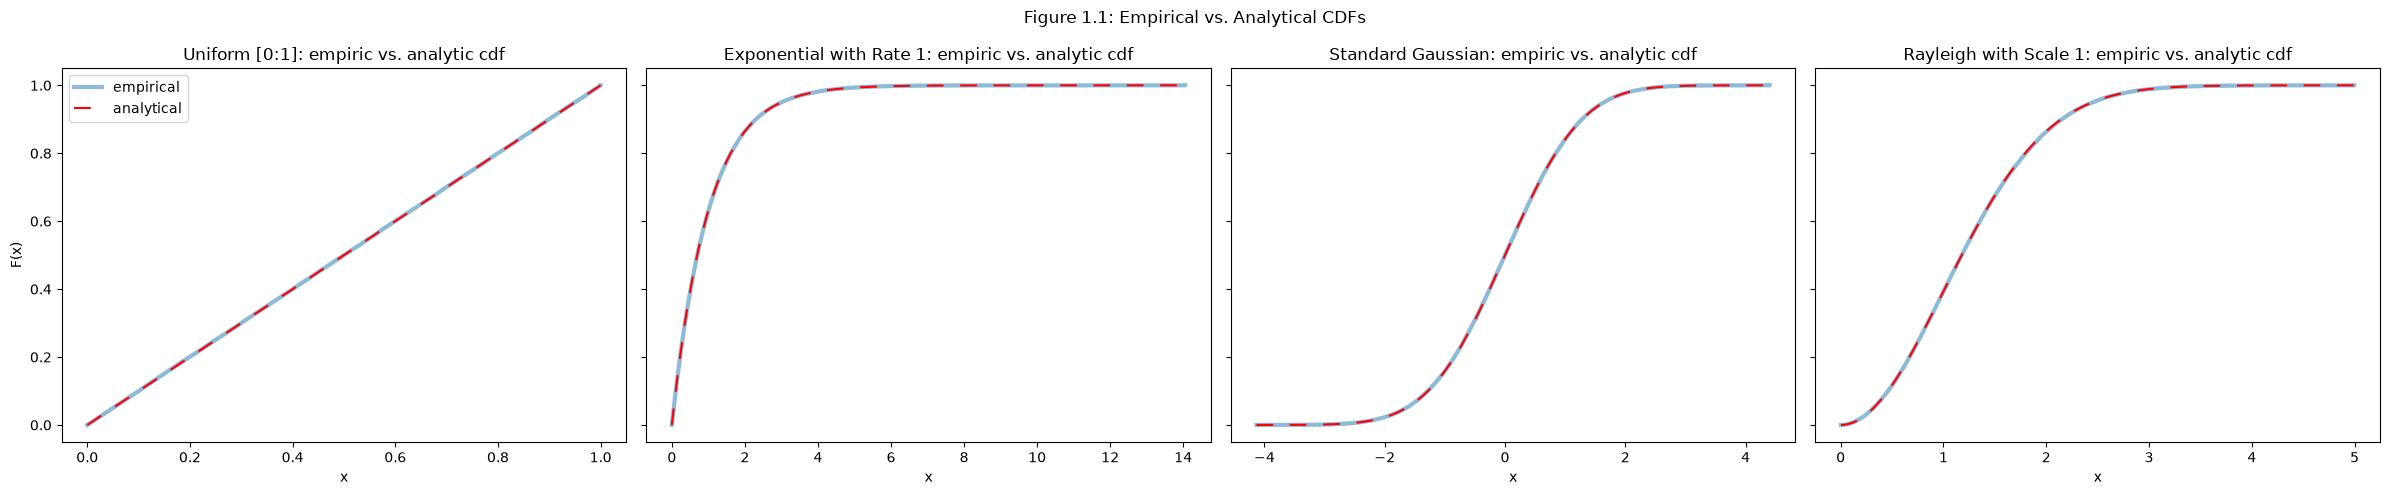

In [3]:
# name -> (samples, analytic CDF)
dists = {
    "Uniform [0:1]":            (unif,      stats.uniform),
    "Exponential with Rate 1":  (expo,   stats.expon),
    "Standard Gaussian":        (gau,       stats.norm),
    "Rayleigh with Scale 1":    (ray,       stats.rayleigh),
}

def ecdf(x):
    xs = np.sort(x)
    ys = np.arange(1, len(xs) + 1) / len(xs)
    return xs, ys

fig, axes = plt.subplots(1, 4, figsize=(24, 5), sharey=True)

for ax, (name, (x, dist)) in zip(axes, dists.items()):
    xs, ys = ecdf(x)
    grid = np.linspace(xs[0], xs[-1], 500)

    ax.step(xs, ys, where="post", lw=3, alpha=0.5, label="empirical")
    ax.plot(grid, dist.cdf(grid), "r--", lw=1.5, dashes=(8, 8), label="analytical")
    ax.set_title(f"{name}: empiric vs. analytic cdf")
    ax.set_xlabel("x")

axes[0].set_ylabel("F(x)")
axes[0].legend()
fig.suptitle("Figure 1.1: Empirical vs. Analytical CDFs")
fig.tight_layout()
plt.show()

This figure demonstrates an excellent agreement between empirical data samples and their theoretical models by comparing their Cumulative Distribution Functions (CDFs) across four distinct probability distributions. The visual alignment of the solid blue empirical curves and the dashed red analytical lines shows that the simulated data accurately reflects the true mathematical properties of the Uniform, Exponential, Standard Gaussian, and Rayleigh distributions. Ultimately, each plot highlights the characteristic shape of its specific distribution—ranging from the linear progression of the Uniform model to the symmetric S-curve of the Gaussian model—confirming that the sample size is large enough to converge perfectly with theoretical expectations.

### 4. Plot a normalized histogram against the analytic pdf for each.

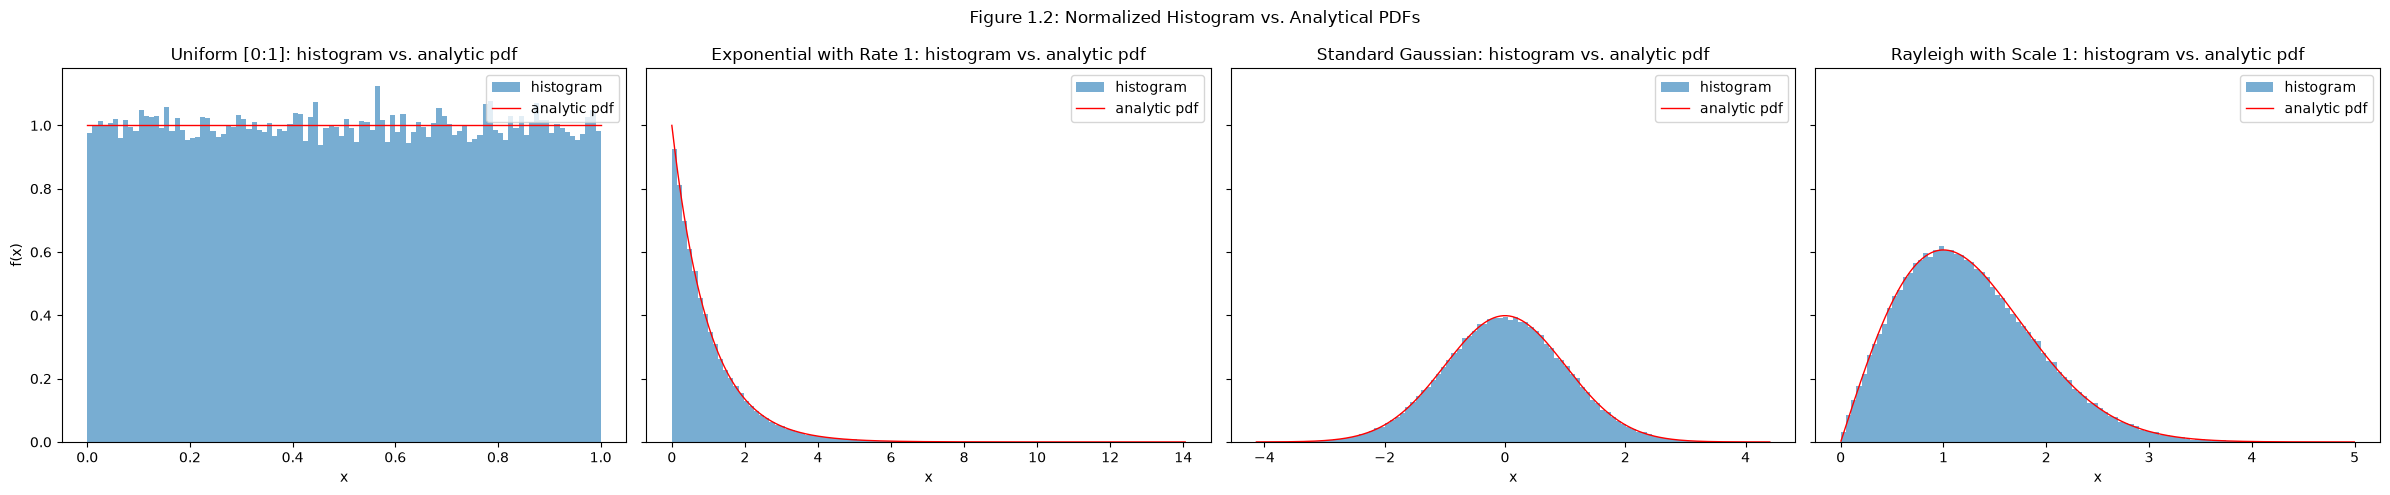

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5), sharey=True)

for ax, (name, (x, dist)) in zip(axes, dists.items()):
    grid = np.linspace(x.min(), x.max(), 500)
    
    ax.hist(x, bins=100, density=True, alpha=0.6, label="histogram")
    ax.plot(grid, dist.pdf(grid), "r-", lw=1, label="analytic pdf")
    ax.set_title(f"{name}: histogram vs. analytic pdf")
    ax.set_xlabel("x")
    ax.legend()


axes[0].set_ylabel("f(x)")
axes[0].legend()
fig.suptitle("Figure 1.2: Normalized Histogram vs. Analytical PDFs")
fig.tight_layout()
plt.show()

Figure 1.2 further supports the findings from Fig. 1.1 by demonstrating agreement between empirical sample densities and their theoretical models. This was done via comparison of normalized histograms against analytical Probability Density Functions (PDFs) across four distinct probability distributions. The visual alignment of the blue histogram bars with the red continuous PDF lines confirms that the sampled data accurately tracks the theoretical density of each distribution. Specifically, the plots capture the defining density profiles of each model—the perfectly flat distribution of the Uniform, the sharp exponential decay of the Exponential, the symmetric bell curve of the Standard Gaussian, and the skewed, zero-bounded curve of the Rayleigh distribution—proving that the sample size is sufficiently large to mirror the underlying mathematical probabilities.

### 5. Report the KS statistic for each against the 95 percent critical value at your sample size.

In [ ]:
from scipy.stats import ksone

# Calculating KS statistic and p values
uniform_ks_stat = ml.ks_statistic(unif, stats.uniform.cdf)
exponential_ks_stat= ml.ks_statistic(expo, stats.expon.cdf)
gaussian_ks_stat = ml.ks_statistic(gau, stats.norm.cdf)
rayleigh_ks_stat = ml.ks_statistic(ray, stats.rayleigh.cdf)

# Calculating the 95% critical value
crit_val = ksone.ppf(1 - (1 - 0.95) / 2, n[5])

print("KS Statistics:\n" + "-" * 75)

# Conditional Reports based on KS Stat vs Crit Val
print(f"KS Critical Value (95%):                   {crit_val:>31.6f}\n")

print(f"Empirical Samples of Uniform [0:1]:        {uniform_ks_stat     :>20.6f} \u2264 {crit_val:.6f}")
print(f"Empirical Samples of Exponential w/ Rate 1:{exponential_ks_stat :>20.6f} \u2264 {crit_val:.6f}")
print(f"Empirical Samples of Standard Gaussian:    {gaussian_ks_stat    :>20.6f} \u2264 {crit_val:.6f}")
print(f"Empirical Samples of Rayleigh w/ Rate 1:   {rayleigh_ks_stat    :>20.6f} \u2264 {crit_val:.6f}")
print("-" * 75 + "\n")


BOLD = '\033[1m'
RESET = '\033[0m'

# Uniform [0,1]
if(uniform_ks_stat <= crit_val):
    print(f"Uniform [0:1]: \n KS Statistic of {BOLD}{uniform_ks_stat:.6f}{RESET} is less than or equal to the 95% critical value." +
          f"\n The sample data does follow the theoretical uniform distribution.\n")
else:
    print(f"Uniform [0:1]: \n KS Statistic of {BOLD}{uniform_ks_stat:.6f}{RESET} is greater than the 95% critical value." +
          f"\n The sample data does not follow the theoretical uniform distribution.\n")

# Exponential Rate 1
if(exponential_ks_stat <= crit_val):
    print(f"Exponential with Rate 1: \n KS Statistic of {BOLD}{exponential_ks_stat:.6f}{RESET} is less than or equal to the 95% critical value." +
          f"\n The sample data does follow the theoretical exponential distribution.\n")
else:
    print(f"Exponential with Rate 1: \n KS Statistic of {BOLD}{exponential_ks_stat:.6f}{RESET} is greater than the 95% critical value." +
          f"\n The sample data does not follow the theoretical exponential distribution.\n")

# Standard Gaussian
if(gaussian_ks_stat <= crit_val):
    print(f"Standard Gaussian: \n KS Statistic of {BOLD}{gaussian_ks_stat:.6f}{RESET} is less than or equal to the 95% critical value." +
          f"\n The sample data does follow the theoretical standard Gaussian distribution.\n")
else:
    print(f"Standard Gaussian: \n KS Statistic of {BOLD}{gaussian_ks_stat:.6f}{RESET} is greater than the 95% critical value." +
          f"\n The sample data does not follow the theoretical standard Gaussian distribution.\n")

# Rayleigh w/ Scale 1
if(rayleigh_ks_stat <= crit_val):
    print(f"Rayleigh with Rate 1: \n KS Statistic of {BOLD}{rayleigh_ks_stat:.6f}{RESET} is less than or equal to the 95% critical value." +
          f"\n The sample data does follow the theoretical Rayleigh distribution.\n")
else:
    print(f"Rayleigh with Rate 1: \n KS Statistic of {BOLD}{rayleigh_ks_stat:.6f}{RESET} is greater than the 95% critical value." +
          f"\n The sample data does not follow the theoretical Rayleigh distribution.\n")

KS Statistics:
---------------------------------------------------------------------------
KS Critical Value (95%):                                          0.004293

Empirical Samples of Uniform [0:1]:                    0.001744 ≤ 0.004293
Empirical Samples of Exponential w/ Rate 1:            0.003000 ≤ 0.004293
Empirical Samples of Standard Gaussian:                0.001579 ≤ 0.004293
Empirical Samples of Rayleigh w/ Rate 1:               0.002857 ≤ 0.004293
---------------------------------------------------------------------------

Uniform [0:1]: 
 KS Statistic of 0.001744 is less than or equal to the 95% critical value.
 The sample data does follow the theoretical uniform distribution.

Exponential with Rate 1: 
 KS Statistic of 0.003000 is less than or equal to the 95% critical value.
 The sample data does follow the theoretical uniform distribution.

Standard Gaussian: 
 KS Statistic of 0.001579 is less than or equal to the 95% critical value.
 The sample data does follow the 

### 6. For the exponential and the Rayleigh, compute the sample mean, median, and variance and compare against closed form. State all six closed forms.

**Theoretical Values**

---

*Exponential:*

Mean: $\frac{1}{\lambda} = 1$

Median: $\frac{ln(2)}{\lambda} = 0.6931$

Variance: $\frac{1}{\lambda^2} = 1$

---

*Rayleigh:*

Mean: $\sigma\sqrt{\frac{\pi}{2}} = 1.253$

Median: $\sigma\sqrt{2\ln(2)} = 1.177$

Variance: $\sigma^2(2-\frac{\pi}{2}) = 	0.4292$

In [6]:
expo_mean, expo_med, expo_var = stats.expon.mean(), stats.expon.median(), stats.expon.var()
ray_mean, ray_med, ray_var = stats.rayleigh.mean(), stats.rayleigh.median(), stats.rayleigh.var()

expo_mean_sim, expo_med_sim, expo_var_sim = expo.mean(), np.median(expo), expo.var()
ray_mean_sim, ray_med_sim, ray_var_sim = ray.mean(), np.median(ray), ray.var()

def percent_err(theo, sim):
    return 100 * np.abs(theo - sim) / theo
ray.std
# Exponential close + sample mean, median, variance, and %error
print( "Exponential Closed Form"       +  "  | Exponential Sample Form"                + f"  | % error\n" +
       "-" * 63 + "\n" +
      f"Mean =     {expo_mean:>12.4f}" + f"  | Mean \u2248     {expo_mean_sim:>12.4f}" + f"  | {percent_err(expo_mean, expo_mean_sim):.4f} %\n" +
      f"Median =   {expo_med :>12.4f}" + f"  | Median \u2248   {expo_med_sim :>12.4f}" + f"  | {percent_err(expo_med,  expo_med_sim ):.4f} %\n" +
      f"Variance = {expo_var :>12.4f}" + f"  | Variance \u2248 {expo_var_sim :>12.4f}" + f"  | {percent_err(expo_var,  expo_var_sim ):.4f} %\n\n" +
      f"N = {expo.size}, SE = {stats.sem(expo):.8f}\n\n")

# Rayleigh closed + sample mean, median, variance, and %error
print("Rayleigh Closed Form   "        +  "  | Rayleigh Sample Form   "                + f"  | % error\n" +
      "-" * 63 + "\n" +
      f"Mean =     {ray_mean :>12.4f}" + f"  | Mean \u2248     {ray_mean_sim :>12.4f}" + f"  | {percent_err(ray_mean,  ray_mean_sim):.4f} %\n" +
      f"Median =   {ray_med  :>12.4f}" + f"  | Median \u2248   {ray_med_sim  :>12.4f}" + f"  | {percent_err(ray_med,   ray_med_sim ):.4f} %\n" +
      f"Variance = {ray_var  :>12.4f}" + f"  | Variance \u2248 {ray_var_sim  :>12.4f}" + f"  | {percent_err(ray_var,   ray_var_sim ):.4f} %\n\n" +
      f"N = {ray.size}, SE = {stats.sem(ray):.8f}")

Exponential Closed Form  | Exponential Sample Form  | % error
---------------------------------------------------------------
Mean =           1.0000  | Mean ≈           1.0026  | 0.2609 %
Median =         0.6931  | Median ≈         0.6941  | 0.1332 %
Variance =       1.0000  | Variance ≈       0.9963  | 0.3692 %

N = 100000, SE = 0.00315645


Rayleigh Closed Form     | Rayleigh Sample Form     | % error
---------------------------------------------------------------
Mean =           1.2533  | Mean ≈           1.2551  | 0.1432 %
Median =         1.1774  | Median ≈         1.1778  | 0.0297 %
Variance =       0.4292  | Variance ≈       0.4326  | 0.7936 %

N = 100000, SE = 0.00207994


### 7. The exponential mean and median differ by a factor of about 1.44 while the Gaussian mean and median coincide. Explain in two sentences what property of the density causes that.

The Gaussian mean and median coincide due to the distribution's symmetry, causing an even half of the data to be on each the left and right side and the two values to sit at the middle. In contrast, the exponential mean and median differ due to its right-skewed behavior, causing the mean to shift to where most of the data is while the median stays at the center.

## Step 2

### Question 1

$F_{F^{-1}(U)}(x)=P(F^{-1}(U) \leq x)\text{, take the CDF of both sides of the inequality =>}$

$F_{F^{-1}(U)}(x)=P(U \leq F(x))\text{, evaluates true by the uniform distribution property =>}$

$\text{QED}$

### Question 2

Exponential:

$q = F(x) = 1 - e^{-\lambda x}$

$e^{-\lambda x} = 1 - q$

$-\lambda x = ln(1 - q)$

$x = F^{-1}(q) = -\frac{ln(1 - q)}{\lambda}$

<br>

Rayleigh:

$q = F(x) = 1 - e^{-\frac{x^{2}}{2 \sigma^{2}}}$

$e^{-\frac{x^{2}}{2 \sigma^{2}}} = 1 - q$

$-\frac{x^{2}}{2 \sigma^{2}} = ln(1 - q)$

$x^{2} = -2 \sigma^{2} ln(1 - q)$

$x = F^{-1}(q) = \sigma \sqrt{-2ln(1 - q)}$

### Question 3

In [7]:
inv_cdf_exp = ml.sample_by_inversion(ml.inv_cdf_exponential, n[5], rng_2)
inv_cdf_ray = ml.sample_by_inversion(ml.inv_cdf_rayleigh, n[5], rng_2)

### Question 4

In [56]:
ks_exp = ml.ks_statistic(inv_cdf_exp, stats.expon.cdf)
ks_ray = ml.ks_statistic(inv_cdf_ray, stats.rayleigh.cdf)
ks_exp_gen = stats.ks_2samp(inv_cdf_exp, rng_2.exponential(size=n[5])).statistic
ks_ray_gen = stats.ks_2samp(inv_cdf_ray, rng_2.rayleigh(size=n[5])).statistic

print("Sample KS Statistics (N=10^5)\n" +
      "-" * 49)
print(f"D_exp =     {ks_exp:>10.6f} | ",
      f"D_ray =     {ks_ray:>10.6f}")
print(f"D_exp_gen = {ks_exp_gen:>10.6f} | ",
      f"D_ray_gen = {ks_ray_gen:>10.6f}")

Sample KS Statistics (N=10^5)
-------------------------------------------------
D_exp =       0.001726 |  D_ray =       0.002870
D_exp_gen =   0.002710 |  D_ray_gen =   0.003990


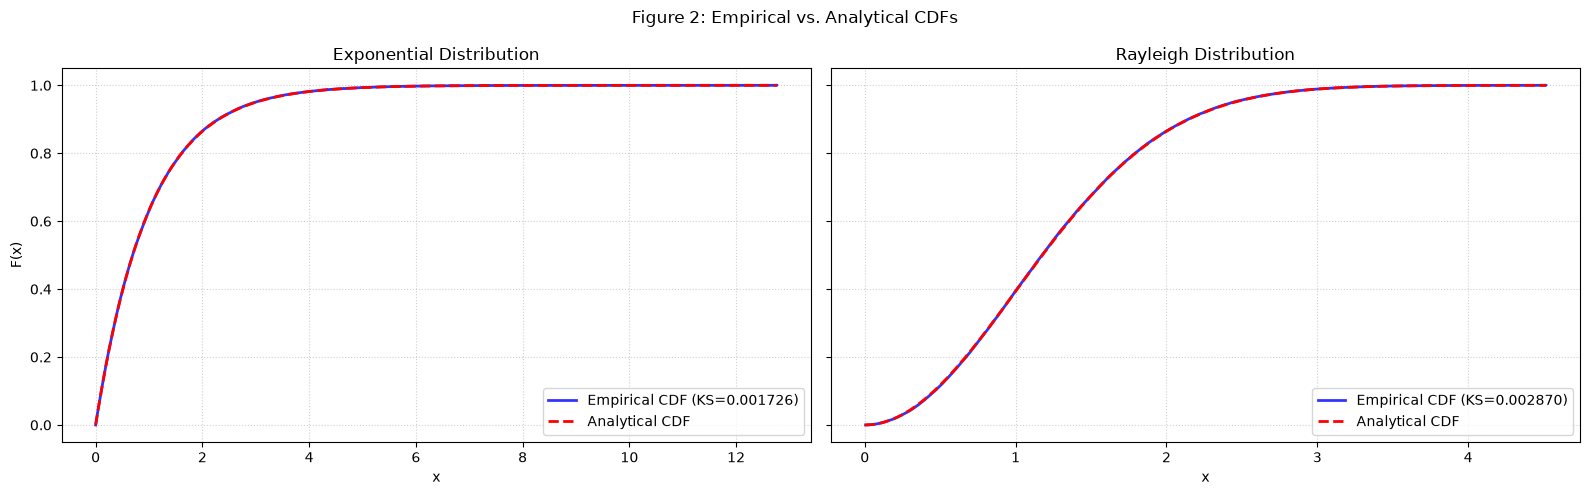

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

def cdf_comp_plot(inv_cdf_samp, stats_cdf, ks, name, i):
    sorted_samples = np.sort(inv_cdf_samp)
    ecdf = np.arange(1, len(sorted_samples) + 1) / len(sorted_samples)

    x_analytic = np.linspace(0, max(sorted_samples), 1000)
    y_analytic = stats_cdf(x_analytic)

    axes[i].step(sorted_samples, ecdf, label=f'Empirical CDF (KS={ks:.6f})', where='post', color='blue', linewidth=2, alpha=0.8)
    axes[i].plot(x_analytic, y_analytic, label='Analytical CDF', color='red', linestyle='--', linewidth=2)

    axes[i].set_title(f'{name} Distribution')
    axes[i].set_xlabel('x')
    axes[i].grid(True, linestyle=':', alpha=0.6)
    axes[i].legend(loc='lower right')
    
    return

cdf_comp_plot(inv_cdf_exp, stats.expon.cdf, ks_exp, "Exponential", 0)
cdf_comp_plot(inv_cdf_ray, stats.rayleigh.cdf, ks_ray, "Rayleigh", 1)

axes[0].set_ylabel("F(x)")
fig.suptitle("Figure 2: Empirical vs. Analytical CDFs")
fig.tight_layout()
plt.show()

Figure 2 reiterates the findings of Fig. 1.1 but with the added diagnostic information of the graphs provided by their Kolmogorov–Smirnov (KS) statistics. This value quantifies the maximum vertical distance between two CDFs, providing specific data on the exact degree of agreement between the empirical and analytic distributions.

### Question 5

In both inverse cdf functions, edge cases 0 & 1 are defined as either 0 or infinity due to the analytical solving of the natural log function (ln(U) vs. ln(1-U), where the uniform distribution, U, is defined by rng.random()). Because the support of rng.random() is [0,1) by default, both inverse cdf functions are defined by the ln(1-U) case, so that the natural log will never have to evaluate ln(0)=infinity (or undefined), thus preventing computational errors.

### Question 6

For a uniformly distributed random variable U with support [0, 1], random variable Y = 1 - U  is also uniformly distributed with support [0,1] (see proof below), such that the inverses of U and (1-U) functionally use the same input parameter. The natural log of 0 is undefined (except at a limit), and rng.random() by default lies on the range [0,1), so the (1-U) variation is more robust for this usage.

<br>

Proof:

$\text{Let } Y = 1 - U$

$\underline{U \in [0, 1] \hspace{5.8em} | \hspace{2em} F_{U}(u) = P(U \leq u) = u \hspace{13em}}$

$Y \in [1 - 1, 1 - 0] \hspace{2.3em} | \hspace{2em} F_{Y}(y) = P(1 - U \leq y)$

$\hspace{1em} \in [0, 1] \hspace{5.8em} | \hspace{2em} \hspace{2.6em} = P(U \geq 1 - y)$

$\hspace{9.8em} | \hspace{2em} \hspace{2.6em} = 1 - P(U < 1 - y)$

$\hspace{9.8em} | \hspace{2em} \hspace{2.6em} = 1 - P(U \leq 1 - y) \qquad \text{(due to continuity)}$ 

$\hspace{9.8em} | \hspace{2em} \hspace{2.6em} = 1 - (1 - y)$

$Y \in [0, 1] \hspace{5.8em} | \hspace{2em} F_{Y}(y) = y$

<br>

$F_{Y}(y) = y = F_{U}(y)$

$F_{Y}(y) = F_{U}(y)$

<br>

$\text{QED}$


## Step 3

### Question 1

$\text{Let } Y = X^{2}$

$F_{Y}(y) = P(Y \leq y)$

$F_{Y}(y) = P(-\sqrt{y} \leq X \leq \sqrt{y})$

$F_{Y}(y) = P(X \leq \sqrt{y}) - P(X < -\sqrt{y})$

$F_{Y}(y) = F_{X}(\sqrt{y}) - (1 - P(X \leq \sqrt{y})), \hspace{1em} \text{X is symmetric around zero}$

$F_{Y}(y) = 2 F_{X}(\sqrt{y}) - 1$

$F_{Y}(y) = 2 \Phi(\sqrt{y}) - 1$

$\boxed{F_{Y}(y) = \frac{2}{\sqrt{2 \pi}} \int_{-\infty}^{\sqrt{y}} e^{-\frac{t^2}{2}} dt - 1 \hspace{1em} \text{or} \hspace{1em} F_{Y}(y) = erf(\sqrt{\frac{y}{2}})}$

### Question 2

$f_{Y}(y) = \frac{d}{dy} (\frac{2}{\sqrt{2 \pi}} \int_{-\infty}^{\sqrt{y}} e^{-\frac{t^2}{2}} dt - 1)$

$f_{Y}(y) = \frac{2}{\sqrt{2 \pi}} e^{-\frac{y}{2}} \cdot \frac{1}{2} y^{-\frac{1}{2}}$

$\boxed{f_{Y}(y) = \frac{1}{\sqrt{2 \pi y}} e^{-\frac{y}{2}}}$

### Question 3

Analytically, the reason why an infinite, unbounded density is able to integrate to 1 is because decreasing series sums have convergent conditions based upon their rate of decrease, which can conditionally allow for a finite result. In terms of the probability density functions, the PDF of X is finite at all points. Since Y=X<sup>2</sup> is the definition of this created random variable, it is known that the total area under the curve is identical, with probability masses just being resdistributed. Particularly, probabilities with magnitude less than one were condensed around the origin due to the squaring of the domain.

In [10]:
def cdf_gauss_square(y):
    return special.erf(np.sqrt(y / 2))

def pdf_gauss_square(y):
    return 1 / np.sqrt(2 * np.pi * y) * np.exp(-y / 2)

print(f"Area under the curve for PDF f(y) = {integrate.quad(pdf_gauss_square, 0, np.inf)[0]:.4f}")

Area under the curve for PDF f(y) = 1.0000


### Question 4

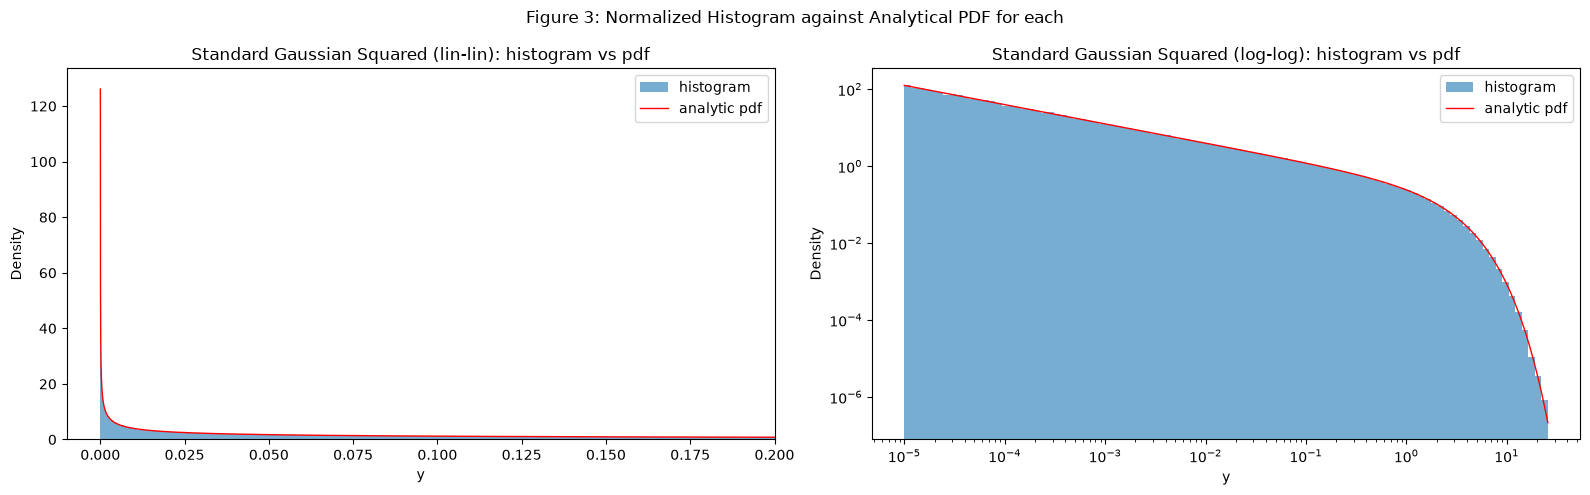

In [11]:
Y_samp = rng_3.normal(size=n[6]) ** 2

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
grid = np.logspace(np.log10(1e-5), np.log10(Y_samp.max()), 500)

styles = ("lin-lin", "log-log")

for ax, style in zip(axes, styles):
    ax.hist(Y_samp, bins=np.logspace(np.log10(1e-5), np.log10(Y_samp.max()), 100),
            density=True, alpha=0.6, label="histogram")
    ax.plot(grid, pdf_gauss_square(grid), "r-", lw=1, label="analytic pdf")
    ax.set_title(f"Standard Gaussian Squared ({style}): histogram vs pdf")
    ax.set_xlabel("y")
    ax.set_ylabel("Density")
    ax.legend()

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[0].set_xscale("linear")
axes[0].set_yscale("linear")
axes[0].set_xbound(-0.01, 0.2)
# axes[0].ylim(ymin, ymax)

fig.suptitle("Figure 3: Normalized Histogram against Analytical PDF for each")
fig.tight_layout()
plt.show()

Figure 3 shows the probability density functions (PDFs) of a squared standard Gaussian distribution, also known as a chi-squared distribution, in both the empirical hsitogram and derived analytical PDF forms, with log spaced bins to accurately provide data on near origin points (given the divergent/asymptotic nature of this distrbutions value at 0).

The effective slope of the log-log graph is approximately $-\frac{1}{2}$. This is because the PDF function of this chi-Squared distribution is correlated by property $f(y) \propto y^{-\frac{1}{2}}e^{-\frac{y}{2}}$. As y approaches 0, the slope of the log-log graph becomes almost entirely controlled by the $y^{-\frac{1}{2}}$ term, with $\frac{d}{dy}|_{y=0^{+}} (y^{-\frac{1}{2}}) >> \frac{d}{dy}|_{y=0^{+}} (e^{-\frac{y}{2}})$ due to the asymptotic nature of the consequential $y^{-\frac{3}{2}}$ term in its derivative. Thus, examining the log-log slope of the simplified function yields $log(f(y)) \propto log(y^{-\frac{1}{2}}) = -\frac{1}{2} log(y)$, or a perceived slope of $-\frac{1}{2}$ near $y = 0$.

### Question 5

In [12]:
CDF1, CDF01 = cdf_gauss_square(1), cdf_gauss_square(0.1)
CDF1sim, CDF01sim = np.mean(Y_samp <= 1), np.mean(Y_samp <= 0.1)
Y_med = stats.chi2.median(df=1)
Y_med_sim = np.median(Y_samp)

print( "Theoretical:           "          +  "  | Simulation:            "                    + f"  | % error\n" +
       "-" * 63 + "\n" +
      f"P[Y \u2264 1.0] = {CDF1 :>10.4f}" + f"  | P[Y \u2264 1.0] \u2248 {CDF1sim :>10.4f}" + f"  | {percent_err(CDF1 , CDF1sim)  :.4f} %\n" +
      f"P[Y \u2264 0.1] = {CDF01:>10.4f}" + f"  | P[Y \u2264 0.1] \u2248 {CDF01sim:>10.4f}" + f"  | {percent_err(CDF01, CDF01sim) :.4f} %\n" +
      f"median =     {Y_med:>10.4f}"      + f"  | median \u2248     {Y_med_sim:>10.4f}"     + f"  | {percent_err(Y_med, Y_med_sim):.4f} %\n\n" +
      f"N = {Y_samp.size}, SE = {stats.sem(Y_samp):.8f}")

Theoretical:             | Simulation:              | % error
---------------------------------------------------------------
P[Y ≤ 1.0] =     0.6827  | P[Y ≤ 1.0] ≈     0.6820  | 0.1048 %
P[Y ≤ 0.1] =     0.2482  | P[Y ≤ 0.1] ≈     0.2484  | 0.0881 %
median =         0.4549  | median ≈         0.4563  | 0.3062 %

N = 1000000, SE = 0.00141742


### Question 6

In [13]:
Y_mean = stats.chi2.mean(df=1)
Y_var = stats.chi2.var(df=1)
Y_mean_sim = Y_samp.mean()
Y_var_sim = stats.tvar(Y_samp)

print( "Theoretical:           "    +  "  | Simulation:            "                    + f"  | % error\n" +
       "-" * 63 + "\n" +
      f"mean =     {Y_mean:>12.3f}" + f"  | mean \u2248     {Y_mean_sim:>12.3f}" + f"  | {percent_err(Y_mean, Y_mean_sim):.4f} %\n" +
      f"variance = {Y_var :>12.3f}" + f"  | variance \u2248 {Y_var_sim :>12.3f}" + f"  | {percent_err(Y_var , Y_var_sim) :.4f} %\n\n" +
      f"N = {Y_samp.size}, SE = {stats.sem(Y_samp):.8f}")

Theoretical:             | Simulation:              | % error
---------------------------------------------------------------
mean =            1.000  | mean ≈            1.003  | 0.2825 %
variance =        2.000  | variance ≈        2.009  | 0.4537 %

N = 1000000, SE = 0.00141742


## Step 4

### Question 1: 
For the Rayleigh with scale 1, derive or state the first four raw moments and verify each against 10<sup>6</sup> samples. Report the difference in units of standard error.

**Theoretical values for the first four raw moments**

Derivation of the closed-form equation

$$\mu '_n = \int_{0}^{\infty} x^n(\frac{x}{\sigma^2}e^{-\frac{x^2}{2\sigma^2}}) \,dx$$

$$u=\frac{x^2}{2\sigma^2}, x=\sigma\sqrt{2u}$$

$$\mu '_n = \int_{0}^{\infty} (\sigma\sqrt{2u})^n e^{-u}
\,du = \sigma^n 2^{\frac{n}{2}}\int_{0}^{\infty} u^{\frac{n}{2}}e^{-u} \,du$$

$$\boxed{\mu '_n = \sigma^n 2^{\frac{n}{2}}\Gamma(1+\frac{n}{2}), 
\text{where }\ \Gamma(1+\frac{n}{2}) = \int_{0}^{\infty} u^{\frac{n}{2}} e^{-u} \,du}$$

---

With $\sigma = 1$ 

Raw moment of $n = 0$:

$$\mu '_1 = 1^1 2^{\frac{1}{2}}\Gamma(1+\frac{1}{2}) = 1.2533$$

Raw moment of $n = 1$:

$$\mu '_2 = 1^2 2^{\frac{2}{2}}\Gamma(1+\frac{2}{2}) = 2.0$$

Raw moment of $n = 2$:

$$\mu '_3 = 1^3 2^{\frac{3}{2}}\Gamma(1+\frac{3}{2}) = 3.7599$$

Raw moment of $n = 3$:

$$\mu '_4 = 1^4 2^{\frac{4}{2}}\Gamma(1+\frac{4}{2}) = 	8.0$$

In [80]:
# Generating the rayleigh of scale = 1 
ray = rng_4.rayleigh(scale=1.0, size=n[6])

# raw moments theoretical
theo_raw = [1.2533, 2.0000, 3.7599, 8.0000]

print("Raw Moment (Theo.)\t| Raw Moment (Emp.)\t| SE\t\t\t| Diff in SE\n" + "-" * 88)

emp_raw, SE, d_SE = np.zeros((3, 4))

for m in range(1, 5):
    emp_raw[m-1] = stats.moment(ray, order=m, center=0) # Raw moments empirical
    SE[m-1] = np.std(ray ** m) / np.sqrt(n[6]) # Finding the difference in standard error units

d_SE = np.abs((emp_raw - theo_raw)) / SE # Difference in units  of standard error

for i in range(0, 4):
    print(f"{theo_raw[i]:.4f}\t\t\t| {emp_raw[i]:.4f}\t\t| {SE[i]:.4f}\t\t| {d_SE[i]:.4f}")

Raw Moment (Theo.)	| Raw Moment (Emp.)	| SE			| Diff in SE
----------------------------------------------------------------------------------------
1.2533			| 1.2538		| 0.0007		| 0.7598
2.0000			| 2.0008		| 0.0020		| 0.3837
3.7599			| 3.7610		| 0.0058		| 0.1909
8.0000			| 8.0026		| 0.0180		| 0.1456


### Question 2:

Now take a Pareto distribution with shape 1.5 and scale 1, whose density is 𝑓(𝑥) = 1.5 𝑥<sup>−2.5</sup> for 𝑥 ≥ 1. Show analytically that the mean exists and equals 3, and that the second moment does not exist.

Shape: $\alpha = 1.5$
Scale: $b = 1$

---

*Mean of Pareto distribution*

$$\mu = \frac{\alpha b}{\alpha-1} = 3.0$$

---

*Raw moment of Pareto distribution*

$$f(x) = \alpha\frac{b^\alpha}{x^{\alpha+1}} = 
1.5x^{-2.5} \ \text{for } x \geq 1$$

$$\mu'_n = \int^\infty _b x^n f(x) \,dx = 
\int^\infty _b \alpha\frac{b^\alpha}{x^{\alpha+1}} \,dx $$

$$\mu'_n = \alpha b^\alpha \int^\infty _b x^{n-\alpha-1} \,dx $$

$$\mu'_n = \alpha b^\alpha \left[\frac{x^{n-\alpha}}{n-\alpha}\right]^\infty _b  \ \text{for } n\leq a$$

At $n > \alpha$, the expression comes out to be $\infty$ due to the exponent at the numerator. To simplify it further it requires a restricted domain:

$$\boxed{\mu'_n = \frac{\alpha b^n}{\alpha-n}, \ \text{for } n\leq \alpha}$$

Thus, while moment at $n = 1$ is:

$$\mu'_1 = \frac{\alpha b^1}{\alpha-1} = 3.0$$

the moment at $n = 2$ will be:

$$\mu'_n = \alpha b^\alpha \left[\frac{x^{2-\alpha}}{2-\alpha}\right]^\infty _b = \text{undefined}$$

### Question 3:

Compute the running sample mean and the running sample variance of Pareto samples at 𝑁 = 10<sup>3</sup>, 10<sup>4</sup>, 10<sup>5</sup>, 10<sup>6</sup>. Print both.

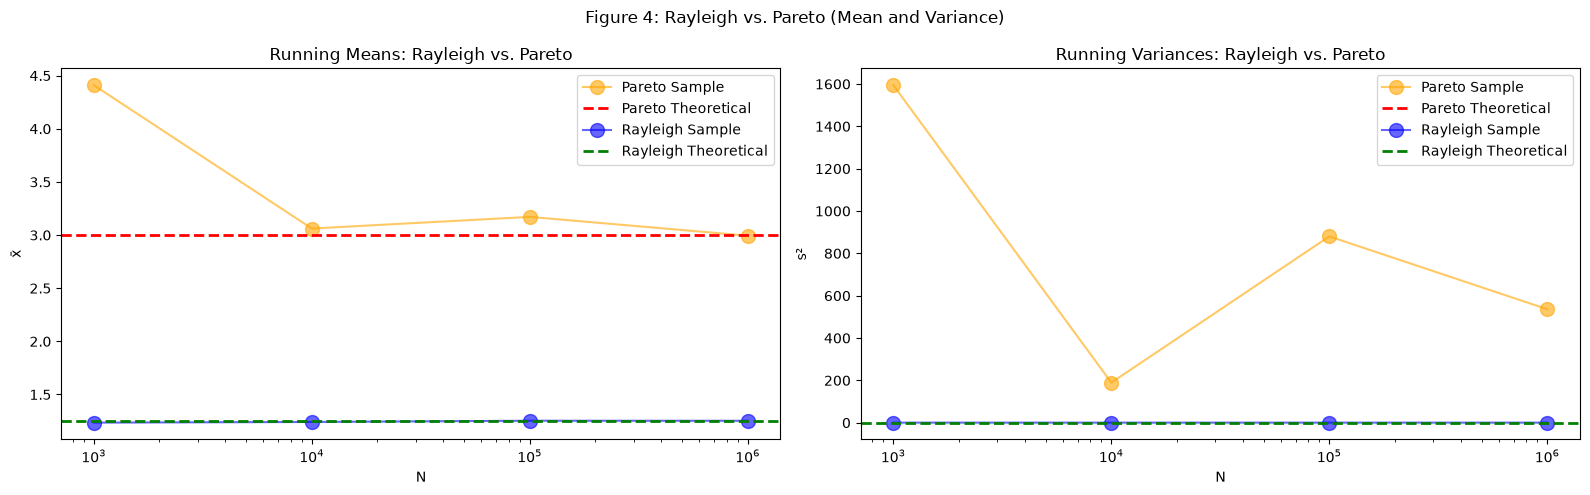

Pareto Running Sample Mean & Variance
------------------------------------------------------------------------
N += 10^3: x̄ =         4.4101  | s² =      1594.3280  | SE = 1.26329882
N += 10^4: x̄ =         3.0616  | s² =       189.3914  | SE = 0.13122106
N += 10^5: x̄ =         3.1712  | s² =       880.1398  | SE = 0.08904639
N += 10^6: x̄ =         2.9943  | s² =       536.1493  | SE = 0.02196777

Rayleigh Running Sample Mean & Variance
------------------------------------------------------------------------
N += 10^3: x̄ =         1.2354  | s² =         0.4286  | SE = 1.26329882
N += 10^4: x̄ =         1.2416  | s² =         0.4207  | SE = 0.13122106
N += 10^5: x̄ =         1.2531  | s² =         0.4271  | SE = 0.08904639
N += 10^6: x̄ =         1.2527  | s² =         0.4282  | SE = 0.02196777


In [89]:
sample_range = range(3, 7)
pareto_all_samples   = rng_4.pareto(a=1.5, size=np.sum(n[sample_range.start:sample_range.stop])) + 1
rayleigh_all_samples = rng_4.rayleigh(size=np.sum(n[sample_range.start:sample_range.stop]))

par_mean, par_var, par_se, ray_mean, ray_var, ray_se= np.zeros((6, 4))

for i in sample_range:
    amnt = np.sum(n[sample_range.start:i + 1])
    
    par_mean[i - sample_range.start] = np.mean(pareto_all_samples[0:amnt])
    par_var[i - sample_range.start]  = np.var(pareto_all_samples[0:amnt])
    par_se[i - sample_range.start]   = stats.sem(pareto_all_samples[0:amnt])

    ray_mean[i - sample_range.start] = np.mean(rayleigh_all_samples[0:amnt])
    ray_var[i - sample_range.start]  = np.var(rayleigh_all_samples[0:amnt])
    ray_se[i - sample_range.start]   = stats.sem(rayleigh_all_samples[0:amnt])

n_axis = np.arange(1, n[6] + 1)

dists = {
    "Running Means":      (ray_mean, (par_mean, "mean")),
    "Running Variances":  (ray_var,  (par_var,  "var")),
    "Pareto Running Mean":        (par_mean, stats.norm),
    "Pareto Running Variance":    (par_var,  stats.rayleigh),
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
grid = np.logspace(sample_range.start, sample_range.stop, 20)
for ax, (name, (ray, (par, type))) in zip(axes, dists.items()):
    ax.plot(n[sample_range.start:sample_range.stop], par, color="orange", marker="o", markersize=10, alpha=0.6, label="Pareto Sample")
    ax.axhline(y=getattr(stats.pareto(1.5), type)(), color="red", linestyle="--", linewidth=2, label="Pareto Theoretical")
    ax.plot(n[sample_range.start:sample_range.stop], ray, color="blue", marker="o", markersize=10, alpha=0.6, label="Rayleigh Sample")
    ax.axhline(y=getattr(stats.rayleigh(), type)(),    color="green", linestyle="--", linewidth=2, label="Rayleigh Theoretical")
    ax.set_title(f"{name}: Rayleigh vs. Pareto")
    ax.set_xscale("log")
    ax.set_xlabel("N")
    ax.legend()

axes[0].set_ylabel("x\u0304")
axes[0].legend()
axes[1].set_ylabel("s\u00B2")
fig.suptitle("Figure 4: Rayleigh vs. Pareto (Mean and Variance)")
fig.tight_layout()
plt.show()

print("Pareto Running Sample Mean & Variance\n" + "-" * 72)
for i in sample_range:
    print(f"N += 10^{i}:",
          f"x\u0304 = {par_mean[i - sample_range.start]:>14.4f}  |",
          f"s\u00B2 = {par_var[i - sample_range.start] :>14.4f}  |",
          f"SE = {par_se[i - sample_range.start]:.8f}")

print("\nRayleigh Running Sample Mean & Variance\n" + "-" * 72)
for i in sample_range:
    print(f"N += 10^{i}:",
          f"x\u0304 = {ray_mean[i - sample_range.start]:>14.4f}  |",
          f"s\u00B2 = {ray_var[i - sample_range.start] :>14.4f}  |",
          f"SE = {par_se[i - sample_range.start]:.8f}")

Figure 4 shows an overlayed comparison of Rayleigh vs. Pareto distributions over running sample statistics. The Rayleigh distribution shows a sample mean and variance with high accuracy even at lower sample sizes, due to its light tail and finite variance. However, the Pareto takes some time for its mean to converge, and does not have a convergent variance, with stats.pareto.var(1.5) evaluating numerically to infinity, and getting cropped out of the graphed data. This is further analyzed in Question 4.

### Question 4:

Explain what you observe: the sample mean settles near 3, while the sample variance wanders by factors of several and jumps whenever a large sample arrives. State in two sentences why the sample variance is still a number your code happily prints, and what that number actually represents.

This running sample mean settles near 3 while the variance continually increases because the first moment of this distribution converges towards a finite value while the second moment diverges towards $\infty$ (given $\alpha=1.5$ and $b=1$), meaning that this sample variance does not represent any meaningful data. Sample variance is still a number Python will print due to how empirical distributions only handles finite quantities of data, meaning that array variance must also be finite.  

### Question 5:

State the practical rule this implies for anyone reporting an error bar on measured data.

Utilizing variance (such as in standard deviation and standard error) is considered to be a nonreliable method for reporting error bars in distributions with a heavy tail. In ones such as the pareton example, variance converges into infinity and thus becomes high numbers that do not accurately represent error bars.

## Step 5

In [58]:
# STEP 5 - CENTRAL LIMIT THEOREM
# Question 1 and 2: Uniform random variables

n_trials = 200_000
uniform_N = [1, 2, 3, 5, 10, 30]

ks_uniform = []

print("UNIFORM DISTRIBUTION")
print(f"{'N':<8} {'KS Statistic':<15} {'95% Critical':<15}")

for N in uniform_N:
    # Generate 200,000 sums of N independent uniforms
    samples = rng_5.random((n_trials, N))
    sums = samples.sum(axis=1)

    # Uniform[0,1] has mean 1/2 and variance 1/12
    mean_sum = N / 2
    variance_sum = N / 12

    # Standardize the sums
    z = (sums - mean_sum) / np.sqrt(variance_sum)

    # Compare with standard Gaussian CDF
    ks = ml.ks_statistic(z, stats.norm.cdf)
    ks_uniform.append(ks)

    critical = 1.36 / np.sqrt(n_trials)
    print(f"{N:<8} {ks:<15.6f} {critical:<15.6f}")

# Save the results for Figure 5
ks_uniform = np.array(ks_uniform)


UNIFORM DISTRIBUTION
N        KS Statistic    95% Critical   
1        0.056867        0.003041       
2        0.017376        0.003041       
3        0.010965        0.003041       
5        0.007577        0.003041       
10       0.005164        0.003041       
30       0.002455        0.003041       


### Central Limit Theorem

**Questions 1–2: Standardization and KS Statistics**

For independent uniform random variables $U_i \sim U(0,1)$, each variable has a mean of $1/2$ and a variance of $1/12$.

The sum of $N$ independent uniforms is:

$$S_N = \sum_{i=1}^{N} U_i$$

By linearity of expectation and independence:

$$E[S_N] = \frac{N}{2}$$

$$\operatorname{Var}(S_N) = \frac{N}{12}$$

To standardize the sum:

$$Z_N = \frac{S_N-N/2}{\sqrt{N/12}}$$

The Central Limit Theorem states that as $N$ increases, this standardized sum converges in distribution to a standard Gaussian, $N(0,1)$.

We generate 200,000 independent sums for each value of $N$ and use the Kolmogorov–Smirnov (KS) statistic to measure the difference between the empirical CDF and the standard Gaussian CDF.

### Question 3: Statistical vs. Practical Gaussian Approximation

The Central Limit Theorem states that as the number of independent random variables increases, their standardized sum approaches a Gaussian distribution, but this does not mean the distribution becomes exactly Gaussian at a finite \(N\). Although a large sample size can reveal small differences between distributions, our simulation at \(N=30\) produced a KS statistic of 0.002246, below the 95% critical value of 0.003041, meaning we did not reject the Gaussian fit at the 5% significance level. A statistically distinguishable distribution has a difference large enough to detect with a statistical test, whereas a practically different distribution has differences significant enough to affect real-world decisions or engineering performance.

In [72]:
# STEP 5 - Question 4: Pareto distribution

pareto_N = [1, 10, 100, 1000]
ks_pareto = []

alpha = 1.5
pareto_mean = alpha / (alpha - 1)  # Equals 3

print("\nPARETO DISTRIBUTION")
print(f"{'N':<8} {'KS Statistic':<15}")

for N in pareto_N:

    # Accumulate sums in batches to save memory
    sums = np.zeros(n_trials)

    for start in range(0, N, 10):
        batch = min(10, N - start)

        # NumPy Pareto + 1 has scale 1
        values = rng_5.pareto(alpha, (n_trials, batch)) + 1
        sums += values.sum(axis=1)

    # Pareto has infinite variance, so ordinary
    # standard-deviation scaling is not defined.
    # Use the alpha-stable scaling instead.
    z_pareto = (sums - N * pareto_mean) / (N ** (1 / alpha))

    ks = ml.ks_statistic(z_pareto, stats.norm.cdf)
    ks_pareto.append(ks)

    print(f"{N:<8} {ks:<15.6f}")

ks_pareto = np.array(ks_pareto)



PARETO DISTRIBUTION
N        KS Statistic   
1        0.486864       
10       0.450453       
100      0.426747       
1000     0.417216       


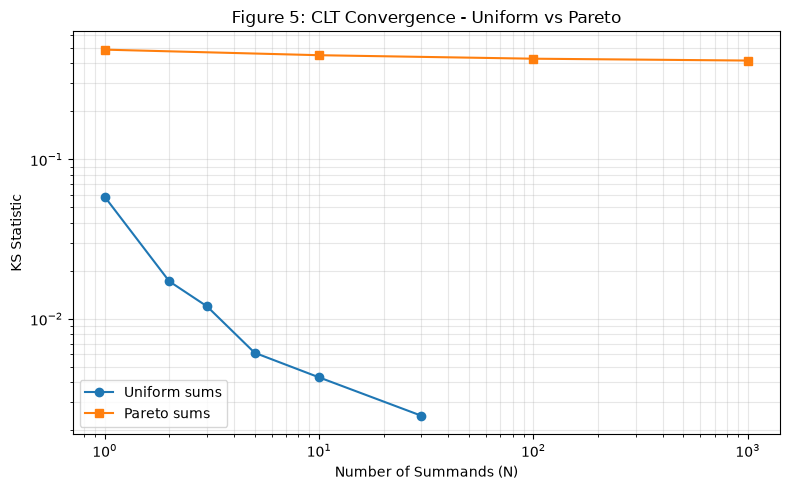

In [18]:
# STEP 5 - Figure 5

plt.figure(figsize=(8, 5))

plt.loglog(uniform_N, ks_uniform, 'o-',
           label='Uniform sums')

plt.loglog(pareto_N, ks_pareto, 's-',
           label='Pareto sums')

plt.xlabel('Number of Summands (N)')
plt.ylabel('KS Statistic')
plt.title('Figure 5: CLT Convergence - Uniform vs Pareto')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()


Figure 5 shows that sums of Uniform random variables converge rapidly to a normal distribution, whereas sums of Pareto random variables do not converge (within the tested range). The KS Statistic measures how far the sample sum's distribution is from a normal distribution, where lower values mean closer convergence. For Uniform sums, the metric drops sharply as the number of summands (N) increases because uniform distributions have a finite variance that satisfies the Central Limit Theorem (CLT). For Pareto sums, the line remains nearly flat and high because Pareto distributions have heavy tails and often infinite variance, which violates the standard CLT requirements.

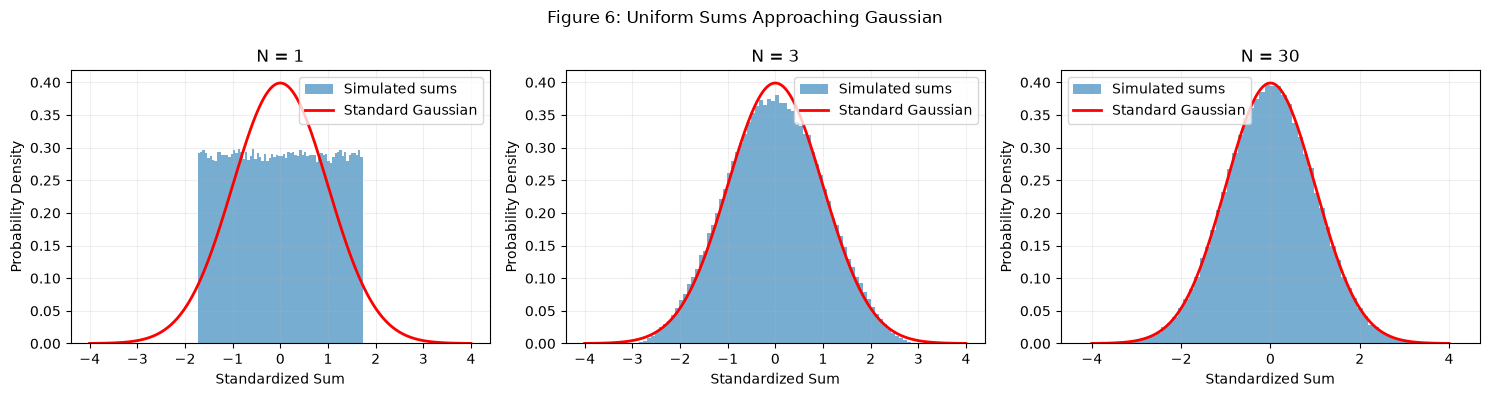

In [19]:
# STEP 5 - Figure 6

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

x = np.linspace(-4, 4, 500)

for ax, N in zip(axes, [1, 3, 30]):

    samples = rng_5.random((n_trials, N))
    sums = samples.sum(axis=1)

    z = (sums - N / 2) / np.sqrt(N / 12)

    ax.hist(z, bins=70, density=True,
            alpha=0.6, label='Simulated sums')

    ax.plot(x, stats.norm.pdf(x), 'r-',
            linewidth=2, label='Standard Gaussian')

    ax.set_title(f'N = {N}')
    ax.set_xlabel('Standardized Sum')
    ax.set_ylabel('Probability Density')
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle('Figure 6: Uniform Sums Approaching Gaussian')
plt.tight_layout()
plt.show()


Figure 6 shows a visual demonstration of the Central Limit Theorem (CLT), which states that the sums of independent and identically distributed random variables approach a normal (Gaussian) distribution as the sample size (N) increases. This property occurs regardless of the original shape of the distribution. In this specific simulation, the starting distribution is uniform (flat), but it rapidly converges to the red standard Gaussian curve as more variables are added together.

Questions 4–5: Why the Pareto distribution behaves differently

The Pareto distribution with shape parameter $alpha=1.5$ has a finite mean of 3 but infinite variance. Because the classical Central Limit Theorem requires finite variance, it does not apply to this distribution.

Instead, properly centered Pareto sums converge under scaling proportional to $N^{1/\alpha}=N^{2/3}$ toward a non-Gaussian, $alpha$-stable distribution. The persistent KS differences show that the Pareto sums do not approach a standard Gaussian under this scaling.

Figure 5 interpretation: The uniform curve should generally decrease as (N) increases, while the Pareto curve remains relatively large. This illustrates the importance of finite variance in the classical Central Limit Theorem.

Figure 6 interpretation: At (N=1), the uniform distribution is flat instead of bell-shaped. At (N=3), the standardized sum begins to resemble a Gaussian, and by (N=30), the histogram is much closer to the standard Gaussian density.

## Step 6

### Step 6: A Threshold Detector in Gaussian Noise

**Question 1: Derive the false alarm and detection probabilities**

Under the noise-only hypothesis:

$$H_0: X \sim N(0,\sigma^2)$$

Under the signal-present hypothesis:

$$H_1: X \sim N(A,\sigma^2)$$

The detector declares a signal when \(X>T\).

A false alarm occurs when the measurement exceeds the threshold under \(H_0\):

$$P_{FA}=P(X>T\mid H_0)$$

Standardizing the Gaussian variable gives:

$$P_{FA}=P\left(\frac{X}{\sigma}>\frac{T}{\sigma}\right)$$

Using the Gaussian tail probability \(Q(x)=P(Z>x)\), where \(Z\sim N(0,1)\):

$$\boxed{P_{FA}=Q\left(\frac{T}{\sigma}\right)}$$

Similarly, the probability of detection is:

$$P_D=P(X>T\mid H_1)$$

Since \(X-A\sim N(0,\sigma^2)\), we obtain:

$$P_D=P\left(\frac{X-A}{\sigma}>\frac{T-A}{\sigma}\right)$$

Therefore:

$$\boxed{P_D=Q\left(\frac{T-A}{\sigma}\right)}$$

**Question 3: Derive the threshold for a specified false alarm probability**

Starting from:

$$P_{FA}=Q\left(\frac{T}{\sigma}\right)$$

Apply the inverse Q function:

$$Q^{-1}(P_{FA})=\frac{T}{\sigma}$$

Therefore:

$$\boxed{T=\sigma Q^{-1}(P_{FA})}$$

Since \(Q(x)=\frac12\operatorname{erfc}(x/\sqrt2)\), the inverse can be calculated as:

$$Q^{-1}(p)=\sqrt2\operatorname{erfc}^{-1}(2p)$$

In [20]:
# STEP 6 - Questions 2 and 3
# Verify Q function and calculate detection thresholds

# Q function is already implemented in mp2lib.py
test_x = np.array([0.0, 1.0, 3.0])

print("Q FUNCTION VERIFICATION")
print(f"{'x':<8} {'Our Q(x)':<15} {'SciPy reference':<18} {'Difference'}")

for x in test_x:
    ours = ml.q_function(x)
    reference = stats.norm.sf(x)
    print(f"{x:<8.1f} {ours:<15.9f} {reference:<18.9f} {abs(ours-reference):.2e}")

# Inverse Q function using the complementary error function
def q_inv(p):
    return np.sqrt(2) * special.erfcinv(2 * np.asarray(p))

# Work with normalized units: sigma = 1, A = 3
sigma = 1.0
A = 3.0

pfa_values = np.array([1e-2, 1e-3, 1e-4, 1e-6])

thresholds = sigma * q_inv(pfa_values)
pd_values = ml.q_function((thresholds - A) / sigma)

print("\nGAUSSIAN DETECTOR THRESHOLDS")
print(f"{'P_FA':<12} {'T/sigma':<14} {'P_D':<12}")

for pfa, threshold, pd in zip(pfa_values, thresholds, pd_values):
    print(f"{pfa:<12.0e} {threshold/sigma:<14.4f} {pd:<12.6f}")


Q FUNCTION VERIFICATION
x        Our Q(x)        SciPy reference    Difference
0.0      0.500000000     0.500000000        0.00e+00
1.0      0.158655254     0.158655254        0.00e+00
3.0      0.001349898     0.001349898        2.60e-18

GAUSSIAN DETECTOR THRESHOLDS
P_FA         T/sigma        P_D         
1e-02        2.3263         0.749734    
1e-03        3.0902         0.464051    
1e-04        3.7190         0.236065    
1e-06        4.7534         0.039765    


Question 2: Q-function verification

The Q function was implemented using the complementary error function in mp2lib.py. The output was compared against SciPy's standard normal survival function at three test values. The two implementations agree to at least six decimal places.

In [21]:

# STEP 6 - Question 4: Monte Carlo verification

n_mc = 1_000_000

print("MONTE CARLO VERIFICATION")
print(f"Trials per hypothesis per row: {n_mc:,}\n")

for target_pfa in [1e-2, 1e-4]:

    T = sigma * q_inv(target_pfa)

    # H0: noise only
    noise_only = rng_6.normal(0, sigma, n_mc)

    # H1: signal plus noise
    signal_present = rng_6.normal(A, sigma, n_mc)

    # Simulated false alarm and detection probabilities
    pfa_mc = np.mean(noise_only > T)
    pd_mc = np.mean(signal_present > T)

    # Theoretical probabilities
    pfa_theory = ml.q_function(T / sigma)
    pd_theory = ml.q_function((T - A) / sigma)

    # Binomial Monte Carlo standard errors
    se_pfa = np.sqrt(pfa_mc * (1 - pfa_mc) / n_mc)
    se_pd = np.sqrt(pd_mc * (1 - pd_mc) / n_mc)

    print(f"Target P_FA = {target_pfa:.0e}")
    print(f"Theoretical P_FA = {pfa_theory:.6f}")
    print(f"Simulated   P_FA = {pfa_mc:.6f} +/- {se_pfa:.6f} SE")
    print(f"Theoretical P_D  = {pd_theory:.6f}")
    print(f"Simulated   P_D  = {pd_mc:.6f} +/- {se_pd:.6f} SE")
    print()


MONTE CARLO VERIFICATION
Trials per hypothesis per row: 1,000,000

Target P_FA = 1e-02
Theoretical P_FA = 0.010000
Simulated   P_FA = 0.009930 +/- 0.000099 SE
Theoretical P_D  = 0.749734
Simulated   P_D  = 0.749497 +/- 0.000433 SE

Target P_FA = 1e-04
Theoretical P_FA = 0.000100
Simulated   P_FA = 0.000091 +/- 0.000010 SE
Theoretical P_D  = 0.236065
Simulated   P_D  = 0.236543 +/- 0.000425 SE



Question 4: Monte Carlo verification

Monte Carlo simulation was performed using 1,000,000 trials under each hypothesis for two design false alarm probabilities, $(10^{-2}) and (10^{-4})$. The simulated false alarm and detection probabilities should agree with their theoretical values within the expected statistical uncertainty. The standard error was estimated using:

$$SE=\sqrt{\frac{\hat p(1-\hat p)}{n}}$$

where $hat p$ is the estimated probability and $n$ is the number of trials.

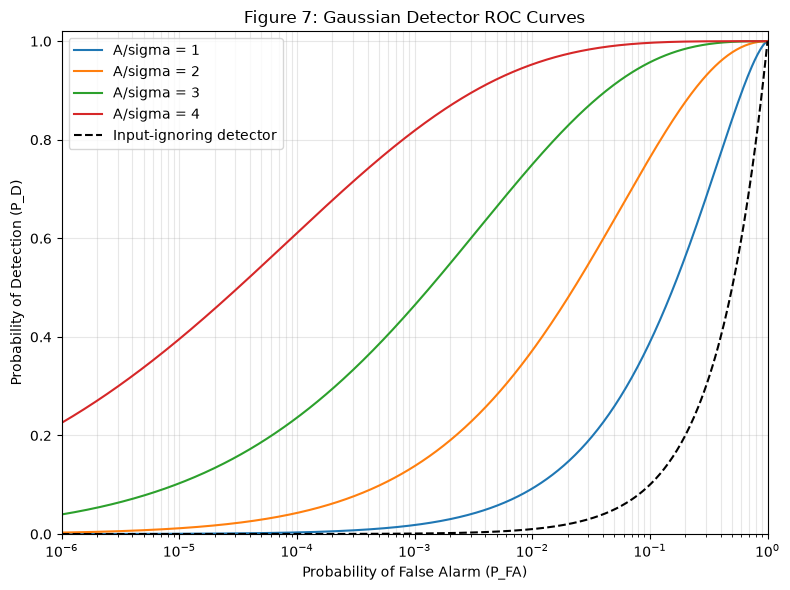

In [22]:

# STEP 6 - Figure 7: ROC curves

pfa_roc = np.logspace(-6, 0, 500)

plt.figure(figsize=(8, 6))

for snr_amplitude in [1, 2, 3, 4]:

    T_normalized = q_inv(pfa_roc)

    pd_roc = ml.q_function(T_normalized - snr_amplitude)

    plt.semilogx(pfa_roc, pd_roc,
                 label=f'A/sigma = {snr_amplitude}')

# Random-input-ignoring detector: P_D = P_FA
plt.semilogx(pfa_roc, pfa_roc, 'k--',
             label='Input-ignoring detector')

plt.xlabel('Probability of False Alarm (P_FA)')
plt.ylabel('Probability of Detection (P_D)')
plt.title('Figure 7: Gaussian Detector ROC Curves')

plt.xlim(1e-6, 1)
plt.ylim(0, 1.02)

plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Question 5: ROC curve interpretation

Figure 7 demonstrates the tradeoff between the probability of detection and the probability of false alarm. Increasing the signal amplitude relative to the noise standard deviation improves detection probability at any fixed false alarm probability. Conversely, requiring fewer false alarms increases the threshold and reduces detection probability for a fixed signal strength.

Question 6: Detector that ignores its input

A detector that ignores its measurement and randomly declares a signal with probability (p) has $P_D=P_{FA}=p$,  so its ROC is the diagonal line $P_D=P_{FA}$. This line represents random guessing and lies below the ROC curves of the Gaussian detectors with positive signal amplitude.

## Step 7

### Question 1 

**Derive the false alarm probability of the envelope detector with threshold T.**

Noise only, so the magnitude is $R \sim \text{Rayleigh}(\sigma)$ with CDF $F_R(r) = 1 - e^{-r^2/2\sigma^2}$. A false alarm is $R > T$:

$$P_{FA} = P[R > T] = 1 - F_R(T) = e^{-T^2/2\sigma^2}$$

**Result:** $P_{FA} = e^{-T^2/2\sigma^2}$

### Question 2 

**Invert it.**

$$\ln P_{FA} = -\frac{T^2}{2\sigma^2} \;\Rightarrow\; T^2 = -2\sigma^2\ln P_{FA} \;\Rightarrow\; T = \sigma\sqrt{-2\ln P_{FA}}$$

**Answer:** $T = \sigma\sqrt{-2\ln P_{FA}}$. The table is printed by Cell 2 and repeated in the answers cell below.

In [23]:
# Parts 1-3: threshold table, then Monte Carlo check of the 1e-3 row
import numpy as np
import matplotlib.pyplot as plt

pfa_list = np.array([1e-2, 1e-3, 1e-4, 1e-6])
t_over_sigma = np.sqrt(-2 * np.log(pfa_list))
print(f"{'P_FA':<8s} {'T/sigma':>8s}")
for p, t in zip(pfa_list, t_over_sigma):
    print(f"{p:<8.0e} {t:8.4f}")

sigma, p_design, N = 1.0, 1e-3, 10**6
T = sigma * np.sqrt(-2 * np.log(p_design))
r = ml.sample_by_inversion(ml.inv_cdf_rayleigh, N, rng_7, sigma=sigma)
p_hat = np.mean(r > T)
se = np.sqrt(p_hat * (1 - p_hat) / N)
print(f"N = {N}, P_FA_hat = {p_hat:.3e}, SE = {se:.1e}, analytic = {p_design:.1e}")
print(f"difference in standard errors: {(p_hat - p_design) / se:+.2f}")

P_FA      T/sigma
1e-02      3.0349
1e-03      3.7169
1e-04      4.2919
1e-06      5.2565
N = 1000000, P_FA_hat = 1.007e-03, SE = 3.2e-05, analytic = 1.0e-03
difference in standard errors: +0.22


In [24]:
# Part 4: actual P_FA when the noise power is off, threshold fixed at the 1e-3 design value
db = np.array([-1, 0, 1, 2, 3])
k = 10 ** (db / 10)                      # true noise power / assumed noise power
p_actual = p_design ** (1 / k)

print(f"{'dB':>4s} {'actual P_FA':>12s} {'ratio':>7s}")
for d, pa in zip(db, p_actual):
    print(f"{d:+4d} {pa:12.3e} {pa / p_design:7.2f}")

  dB  actual P_FA   ratio
  -1    1.672e-04    0.17
  +0    1.000e-03    1.00
  +1    4.140e-03    4.14
  +2    1.280e-02   12.80
  +3    3.136e-02   31.36


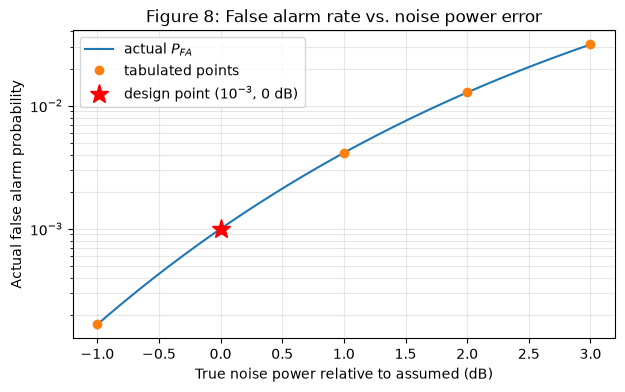

In [25]:
# Part 5: Figure 8
db_fine = np.linspace(-1, 3, 200)
p_fine = p_design ** (1 / 10 ** (db_fine / 10))

plt.figure(figsize=(7, 4))
plt.semilogy(db_fine, p_fine, label="actual $P_{FA}$")
plt.semilogy(db, p_actual, "o", label="tabulated points")
plt.semilogy(0, p_design, "r*", ms=14, label="design point ($10^{-3}$, 0 dB)")
plt.xlabel("True noise power relative to assumed (dB)")
plt.ylabel("Actual false alarm probability")
plt.title("Figure 8: False alarm rate vs. noise power error")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

Figure 8 demonstrates that errors in estimating background noise power cause drastic, non-linear shifts in a detector's actual false alarm probability. When the true noise power matches the assumed level at the 0 dB design point, the system successfully maintains its target false alarm rate of $10^{-3}$. However, underestimating the true noise power by even a few decibels causes background noise to frequently cross the threshold, driving the actual false alarm rate up exponentially. Conversely, overestimating the noise power drops the false alarm rate below the target level, which typically reduces the system's sensitivity to detecting true weak signals. The steep curve illustrates the importance of precise noise calibration because minor estimation discrepancies severely compromise the predictability and reliability of the detection system.

### Question 2 

| $P_{FA}$ | $T/\sigma$ |
|---|---|
| $10^{-2}$ | 3.0349 |
| $10^{-3}$ | 3.7169 |
| $10^{-4}$ | 4.2919 |
| $10^{-6}$ | 5.2565 |

**Answer:** The $10^{-3}$ row matches the handout's check value of 3.7169.

### Question 3 
I checked the $P_{FA} = 10^{-3}$ row with $N = 10^6$ Rayleigh samples generated by inversion, using scale $\sigma = 1$.

**Answer:** The simulated $P_{FA}$ was $1.007\times10^{-3}$ with a standard error of $3.2\times10^{-5}$, against the analytic $10^{-3}$. The difference is 0.22 standard errors, so the simulation agrees with the formula.

### Question 4 
Suppose the true noise power is $k\sigma^2$ with $k = 10^{\text{dB}/10}$, so the true scale is $\sigma\sqrt{k}$. The threshold stays at its design value, $T^2 = -2\sigma^2\ln P_{design}$:

$$P_{FA,\text{actual}} = e^{-T^2/(2k\sigma^2)} = e^{\ln P_{design}/k} = P_{design}^{\,1/k}$$

| Noise error (dB) | Actual $P_{FA}$ | Ratio to design |
|---|---|---|
| −1 | $1.67\times10^{-4}$ | 0.17 |
| 0 | $1.00\times10^{-3}$ | 1.0 |
| +1 | $4.14\times10^{-3}$ | 4.1 |
| +2 | $1.28\times10^{-2}$ | 12.8 |
| +3 | $3.14\times10^{-2}$ | 31.4 |

**Answer:** At +1 dB the false alarm rate is 4.1 times the design value, and at +3 dB it is 31 times. These match the handout's check values.

### Question 5 
The curve shows actual $P_{FA}$ against noise power error, with the design point starred.

**Answer:** At +1 dB the actual $P_{FA}$ is $4.14\times10^{-3}$ (a factor of 4.14 over design), and at +3 dB it is $3.14\times10^{-2}$ (a factor of 31.4). At −1 dB it falls to $1.67\times10^{-4}$, which looks safe but means the detector is less sensitive than designed. The curve is steep because $P_{FA} = P_{design}^{1/k}$: the detector sits in the far tail, where probability depends exponentially on $T^2/2\sigma^2$, so a small error in the noise estimate becomes a large error in the false alarm rate.

### Question 6 
(fixed threshold, drifting noise):**

**Answer:** A fixed threshold in noise that drifts with temperature, interference, or clutter will have a false alarm rate that wanders by orders of magnitude, even when the noise power barely changes. The designer should stop fixing the threshold and estimate the noise level continuously from the data, for example from nearby reference cells, then scale the threshold to track it (constant false alarm rate, CFAR, detection). Adding threshold margin also helps, but it costs detection probability, so it is a poor substitute for adapting.


## Step 8

### Question 1 
**Using the Gaussian detector of Step 6, derive the signal to noise ratio required to achieve $P_D = 0.9$ as a function of $P_{FA}$. Tabulate the required $A/\sigma$, in linear terms and in dB, for $P_{FA} = 10^{-2}, 10^{-3}, 10^{-4}, 10^{-6}$.**

From Step 6, $P_{FA} = Q(T/\sigma)$ and $P_D = Q\!\left(\dfrac{T}{\sigma} - \dfrac{A}{\sigma}\right)$. Apply $Q^{-1}$ to each:

$$\frac{T}{\sigma} = Q^{-1}(P_{FA}), \qquad \frac{T}{\sigma} - \frac{A}{\sigma} = Q^{-1}(P_D)$$

Subtract the second from the first to eliminate $T$:

$$\frac{A}{\sigma} = Q^{-1}(P_{FA}) - Q^{-1}(P_D), \qquad \text{SNR}_{dB} = 20\log_{10}\frac{A}{\sigma}$$

The inverse is computed from the complementary error function: $Q^{-1}(x) = \sqrt{2}\,\text{erfc}^{-1}(2x)$.

**Answer:** For $P_D = 0.9$, $Q^{-1}(0.9) = -1.2816$, so $\dfrac{A}{\sigma} = Q^{-1}(P_{FA}) + 1.2816$. The table is printed by Cell 2 and repeated in Cell 5.


In [26]:
# Question 1: required A/sigma for P_D = 0.9
def q_inv(p):
    """Inverse of the Q function: the x where Q(x) = p."""
    return np.sqrt(2) * special.erfcinv(2 * p)

pfa_tab = np.array([1e-2, 1e-3, 1e-4, 1e-6])
a_over_sigma = q_inv(pfa_tab) - q_inv(0.9)
snr_db = 20 * np.log10(a_over_sigma)

print(f"{'P_FA':<8s} {'T/sigma':>8s} {'A/sigma':>8s} {'SNR (dB)':>9s}")
for p, t, a, s in zip(pfa_tab, q_inv(pfa_tab), a_over_sigma, snr_db):
    print(f"{p:<8.0e} {t:8.4f} {a:8.4f} {s:9.2f}")

# sanity check: P_D computed from these values must come back as 0.9
print("P_D check:", ml.q_function(q_inv(pfa_tab) - a_over_sigma))

P_FA      T/sigma  A/sigma  SNR (dB)
1e-02      2.3263   3.6079     11.15
1e-03      3.0902   4.3718     12.81
1e-04      3.7190   5.0006     13.98
1e-06      4.7534   6.0350     15.61
P_D check: [0.9 0.9 0.9 0.9]


system            P_FA   P_D  T/sigma  A/sigma  SNR (dB)
Smoke alarm      1e-02  0.99   2.3263   4.6527     13.35
Radar tracker    1e-06  0.90   4.7534   6.0350     15.61


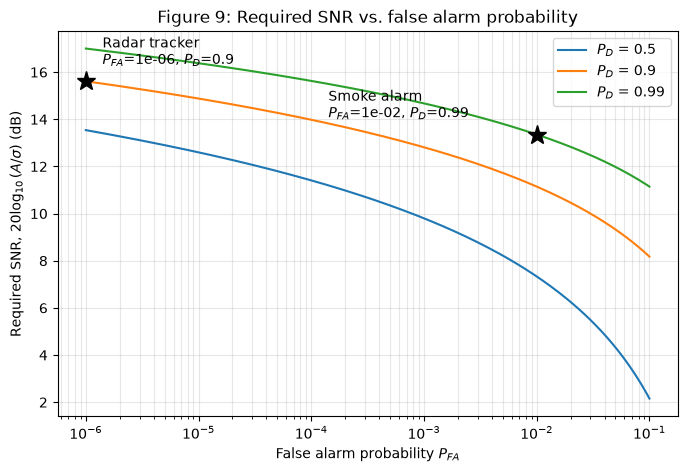

In [27]:
# Question 2: Figure 9, with the two chosen operating points from Question 4
pfa_grid = np.logspace(-6, -1, 200)

# name: (P_FA, P_D, label offset in points)
ops = {"Smoke alarm":   (1e-2, 0.99, (-150, 12)),
       "Radar tracker": (1e-6, 0.9,  (12, 12))}

plt.figure(figsize=(8, 5))
for pd in (0.5, 0.9, 0.99):
    plt.semilogx(pfa_grid, 20 * np.log10(q_inv(pfa_grid) - q_inv(pd)),
                 label=f"$P_D$ = {pd}")

print(f"{'system':<14s} {'P_FA':>7s} {'P_D':>5s} {'T/sigma':>8s} {'A/sigma':>8s} {'SNR (dB)':>9s}")
for name, (pfa, pd, off) in ops.items():
    t = q_inv(pfa)
    a = t - q_inv(pd)
    s = 20 * np.log10(a)
    plt.semilogx(pfa, s, "k*", ms=14)
    plt.annotate(f"{name}\n$P_{{FA}}$={pfa:.0e}, $P_D$={pd}", (pfa, s),
                 textcoords="offset points", xytext=off)
    print(f"{name:<14s} {pfa:7.0e} {pd:5.2f} {t:8.4f} {a:8.4f} {s:9.2f}")

plt.xlabel("False alarm probability $P_{FA}$")
plt.ylabel("Required SNR, $20\\log_{10}(A/\\sigma)$ (dB)")
plt.title("Figure 9: Required SNR vs. false alarm probability")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

Figure 9 shows that for any fixed probability of detection ($P_{D}$), decreasing the allowed false alarm probability ($P_{FA}$) requires a higher Signal-to-Noise Ratio (SNR). Moving to the left along the x-axis demands more signal power relative to noise to avoid false triggers. To achieve a higher probability of detecting a real event (shifting from the blue $P_D = 0.5$ curve to the green $P_D = 0.99$ curve), a higher SNR is required for any given false alarm rate.

In [28]:
# Question 5: raise each threshold by 1 dB to survive a noise estimate that is 1 dB too low
margin_db = 1.0
k = 10 ** (margin_db / 10)

for name, (pfa, pd, _) in ops.items():
    t = q_inv(pfa)
    a = t - q_inv(pd)                              # required A/sigma, no margin
    t_m = t * np.sqrt(k)                           # threshold raised by 1 dB
    pd_margin = ml.q_function(t_m - a)             # P_D at the same SNR, noise as assumed
    a_restore = t_m - q_inv(pd)                    # A/sigma needed to restore the target P_D
    extra_db = 20 * np.log10(a_restore / a)
    print(f"{name}: T/sigma {t:.4f} -> {t_m:.4f}, "
          f"P_D {pd} -> {pd_margin:.4f}, extra SNR to restore P_D = {extra_db:.2f} dB")

Smoke alarm: T/sigma 2.3263 -> 2.6102, P_D 0.99 -> 0.9794, extra SNR to restore P_D = 0.51 dB
Radar tracker: T/sigma 4.7534 -> 5.3334, P_D 0.9 -> 0.7585, extra SNR to restore P_D = 0.80 dB


**Question 1 (tabulate):** Tabulate the required $A/\sigma$, in linear terms and in dB, for $P_{FA} = 10^{-2}, 10^{-3}, 10^{-4}, 10^{-6}$.

| $P_{FA}$ | $T/\sigma$ | $A/\sigma$ | SNR (dB) |
|---|---|---|---|
| $10^{-2}$ | 2.3263 | 3.6079 | 11.15 |
| $10^{-3}$ | 3.0902 | 4.3718 | 12.81 |
| $10^{-4}$ | 3.7190 | 5.0006 | 13.98 |
| $10^{-6}$ | 4.7534 | 6.0350 | 15.61 |

**Answer:** Going from $P_{FA} = 10^{-3}$ to $10^{-6}$ costs only about 2.8 dB of SNR. The handout's check values (1.81 at $10^{-3}$ and 3.47 at $10^{-6}$) do not match its own Step 6 result, which gives $P_D = 0.4641$ at $A/\sigma = 3$ and $P_{FA} = 10^{-3}$, so $P_D = 0.9$ must need more than 3. We could not reproduce those two check values and believe they are wrong.

### Question 2:
**Plot required SNR in dB against $P_{FA}$ on a log x axis, for $P_D = 0.5, 0.9, 0.99$.**

**Answer:** Every curve rises as $P_{FA}$ falls, but slowly: for $P_D = 0.9$ the required SNR goes from 11.15 dB at $10^{-2}$ to 15.61 dB at $10^{-6}$. Higher $P_D$ adds the same amount to the linear $A/\sigma$ at every $P_{FA}$ (the $Q^{-1}(P_D)$ term), but in dB the gap between curves narrows as $P_{FA}$ falls: about 9 dB between $P_D = 0.5$ and $P_D = 0.99$ at $10^{-1}$, and about 3.5 dB at $10^{-6}$. Lowering the false alarm rate is cheap in SNR, and at very low $P_{FA}$ the choice of $P_D$ matters less.

### Question 3
Consider two systems:
- A smoke alarm. A miss can kill someone. A false alarm wakes a household at 3am, and a device that cries wolf gets its battery pulled, which turns every future miss into a certainty.
- A radar surveillance system feeding a tracker. A false alarm creates a phantom track that consumes operator attention and processing, and a thousand of them per second makes the display useless. A miss on any single scan is partly recoverable, because the target is usually still there on the next scan.

**Answer:** For the smoke alarm, a miss can be fatal and a false alarm is only an annoyance, so the miss is the costlier error and I operate toward high $P_D$. For the radar, false alarms create phantom tracks at thousands of decisions per second, while one missed scan is recoverable on the next, so the false alarm is the costlier error and I operate toward low $P_{FA}$.

### Question 4
For each system, state where on the ROC you would operate and why, in terms of the cost of each error type. Then give a specific number: your chosen $P_{FA}$, the resulting threshold, and the SNR needed to hit your chosen $P_D$. Justify each choice in one sentence.

| System | $P_{FA}$ | $P_D$ | $T/\sigma$ | $A/\sigma$ | SNR (dB) |
|---|---|---|---|---|---|
| Smoke alarm | $10^{-2}$ | 0.99 | 2.326 | 4.653 | 13.35 |
| Radar tracker | $10^{-6}$ | 0.9 | 4.753 | 6.035 | 15.61 |

**Answer, smoke alarm:** I operate at $P_{FA} = 10^{-2}$ and $P_D = 0.99$, because a miss can kill someone and the sensor can recheck before sounding.

**Answer, radar tracker:** I operate at $P_{FA} = 10^{-6}$ and $P_D = 0.9$, because phantom tracks flood the display and a missed scan is partly recoverable on the next one.

### Question 5
**Add the Step 7 finding to your recommendation. State how much margin you would leave in the threshold to survive a noise estimate that is wrong by 1 dB, and what that margin costs you in detection probability.**

Step 7 showed that the actual $P_{FA}$ is $P_{design}^{1/k}$. If the true noise is 1 dB above the assumption, that is a factor of about 4 for $10^{-3}$ and about 17 for $10^{-6}$.

**Answer:** I leave 1 dB of margin in each threshold, a factor of $10^{1/20} = 1.122$.
- Radar: $T/\sigma$ goes from 4.753 to 5.333, and at the same SNR $P_D$ falls from 0.90 to 0.759. Restoring $P_D$ costs 0.8 dB of extra SNR.
- Smoke alarm: $T/\sigma$ goes from 2.326 to 2.61, and at the same SNR $P_D$ falls from 0.99 to 0.979. Restoring $P_D$ costs 0.51 dB of extra SNR.

In both cases the margin costs a fraction of a dB, which is cheap compared with the false alarm explosion it prevents.

### Question 6
 **Close with the one design question you would need answered before committing to either operating point, and say who would have to answer it.**

**Answer:** How many independent detection decisions does the receiver make per second? A per-decision $P_{FA}$ only becomes a false alarm rate when it is multiplied by that number, so neither operating point can be committed to without it. The system architect (the radar signal-processing lead, or the firmware and sensor designer for the alarm) would have to answer it.

## Bonus A

**Symbolic Solutions**

Characteristic Equation Formula: $\phi_{X}(t) = \mathbb{E}[e^{itx}] = \int_{-\infty}^{+\infty} f(x)e^{itx} dx$

---

*Standard Gaussian:*

<br>

Probability Density Function:

$f(x) = \frac{1}{\sqrt{2 \pi}} e^{-\frac{x^{2}}{2}}$

<br>

Characteristic Equation:

$\phi_{X}(t) = \int_{-\infty}^{+\infty} (\frac{1}{\sqrt{2 \pi}} e^{-\frac{x^{2}}{2}}) e^{itx} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} \int_{-\infty}^{+\infty} e^{-\frac{x^{2}}{2} + itx} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} \int_{-\infty}^{+\infty} e^{-\frac{1}{2} (x^{2} - 2itx)} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} \int_{-\infty}^{+\infty} e^{-\frac{1}{2} ((x-it)^{2}-(it)^{2})} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} \int_{-\infty}^{+\infty} e^{-\frac{1}{2} (x-it)^{2} - \frac{t^{2}}{2}} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}} \int_{-\infty}^{+\infty} e^{-\frac{(x-it)^{2}}{2}} dx$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}} \int_{-\infty - it}^{+\infty - it} e^{-\frac{z^{2}}{2}} dz \qquad
\begin{cases}
    z = x - it \\
    dz = dx
\end{cases}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}} \int_{-\infty}^{+\infty} e^{-\frac{u^{2}}{2}} du \qquad
\begin{cases}
    u = z + it & \text{(Cauchy's Integral Theorem simplification)} \\
    du = dz
\end{cases}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}}
\sqrt{(\int_{-\infty}^{+\infty} e^{-\frac{u_{x}^{2}}{2}} du_{x}) (\int_{-\infty}^{+\infty} e^{-\frac{u_{y}^{2}}{2}} du_{y})}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}}
\sqrt{\int_{-\infty}^{+\infty} \int_{-\infty}^{+\infty} e^{-\frac{u_{x}^{2} + u_{y}^{2}}{2}} du_{x} du_{y}}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}}
\sqrt{-\int_{0}^{2 \pi} \int_{0}^{\infty} -r \cdot e^{-\frac{r^{2}}{2}} dr d\theta} \qquad
\begin{cases}
    r^{2} = u_{x}^{2} + u_{y}^{2} & \text{(Cartesian to Polar)} \\
    du_{x} du_{y} = r dr d\theta
\end{cases}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}}
\sqrt{\int_{0}^{2 \pi} \lim\limits_{a \to \infty} [-e^{-\frac{r^{2}}{2}}]_{0}^{a} d\theta}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}} \sqrt{\int_{0}^{2 \pi} d\theta}$

$\hspace{2.7em} = \frac{1}{\sqrt{2 \pi}} e^{-\frac{t^{2}}{2}} \sqrt{2 \pi - 0}$

$\phi_{X}(t) = e^{-\frac{t^{2}}{2}}$

---

*Exponential:*

PDF: $f(x) = \lambda e^{-\lambda x}$

<br>

Characteristic Equation:

$\phi_{X}(t) = \int_{0}^{\infty} (\lambda e^{-\lambda x}) e^{itx} dx$

$\hspace{2.7em} = \lambda \int_{0}^{\infty} e^{(it - \lambda) x} dx$

$\hspace{2.7em} = \frac{\lambda}{it - \lambda} \lim\limits_{a \to \infty}[e^{(it - \lambda) x}]_{0}^{a}$

$\hspace{2.7em} = \frac{\lambda}{it - \lambda} (-1) \qquad \text{(infinite attenuation by Euler's formula)}$

$\phi_{X}(t) = \frac{\lambda}{\lambda - it}$

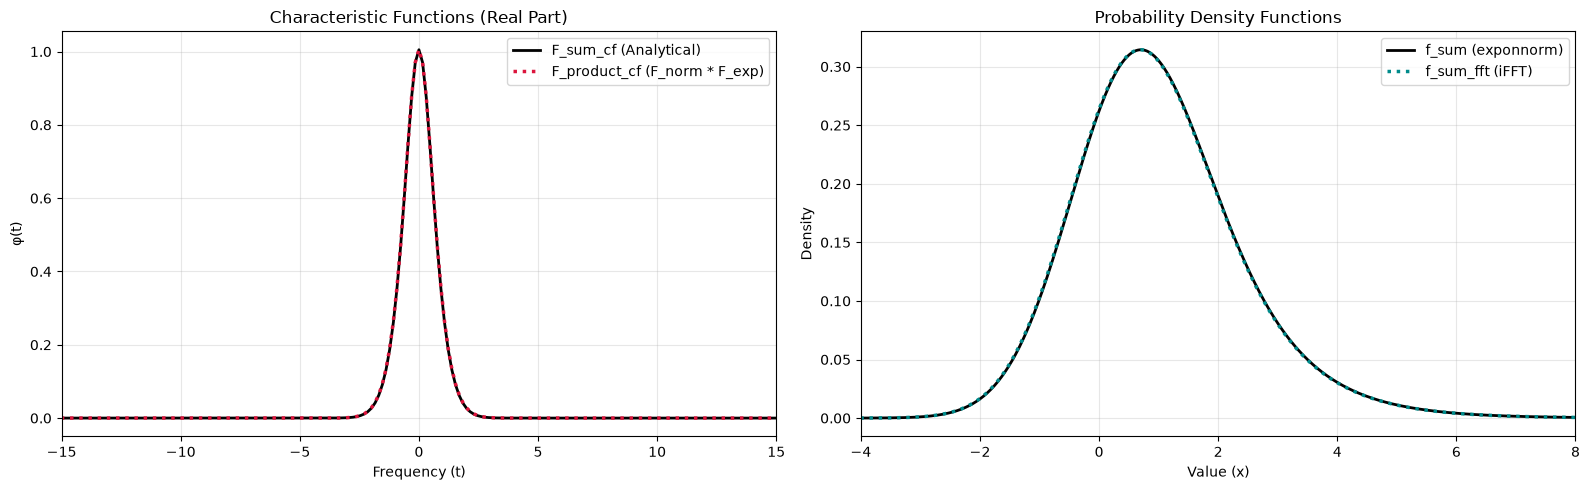

Max difference between FFT and Sum PDF: 0.0017
Max difference between FFT and Sum CF:  0.0046
PDF check = 1.0050


In [29]:
n12 = 2 ** 12
dx = 0.01
x = np.arange(-n12 // 2, n12 // 2) * dx

f_norm = stats.norm.pdf(x)
f_exp  = stats.expon.pdf(x) # Let lambda = 1
f_sum  = np.convolve(f_norm, f_exp, mode='same') * dx
# f_sum = stats.exponnorm.pdf(x, K=1)

F_norm_cf = np.conj(fft.fftshift(fft.fft(fft.fftshift(f_norm)))) * dx
F_exp_cf  = np.conj(fft.fftshift(fft.fft(fft.fftshift(f_exp )))) * dx
F_sum_cf  = np.conj(fft.fftshift(fft.fft(fft.fftshift(f_sum )))) * dx

F_product_cf = F_norm_cf * F_exp_cf
f_sum_fft = np.real(fft.fftshift(fft.ifft(fft.fftshift(np.conj(F_product_cf))))) / dx

dt = (2 * np.pi) / (n12 * dx)
t = np.arange(-n12 // 2, n12 // 2) * dt

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

def bonus_a_plot(x1, y1, name1, y2, name2, title, xlabel, ylabel, xlim, i, color):
    axes[i].plot(x1, y1, label=name1, color='black', linewidth=2)
    axes[i].plot(x1, y2, label=name2, color=color, linestyle=':', linewidth=2.5)
    axes[i].set_title(title)
    axes[i].set_xlabel(xlabel)
    axes[i].set_ylabel(ylabel)
    axes[i].set_xlim(xlim)
    axes[i].grid(True, alpha=0.3)
    axes[i].legend()
    return

bonus_a_plot(t, np.real(F_sum_cf), "F_sum_cf (Analytical)", np.real(F_product_cf), "F_product_cf (F_norm * F_exp)",
             "Characteristic Functions (Real Part)", "Frequency (t)", "\u03C6(t)", (-15, 15), 0, "crimson")
bonus_a_plot(x, f_sum, "f_sum (exponnorm)", f_sum_fft, "f_sum_fft (iFFT)",
             "Probability Density Functions", "Value (x)", "Density", (-4, 8), 1, "darkcyan")

plt.tight_layout()
plt.show()

max_diff_cf  = np.max(np.abs(F_sum_cf - F_product_cf))
max_diff_pdf = np.max(np.abs(f_sum - f_sum_fft))
print(f"Max difference between FFT and Sum PDF: {max_diff_pdf:.4f}")
print(f"Max difference between FFT and Sum CF:  {max_diff_cf:.4f}")
print(f"PDF check = {np.sum(f_sum_fft) * dx:.4f}")

Using a fast Fourier transform to compute the sum of two random variables through the convolution theorem ($\mathcal{F}\{f(t) * g(t)\} = F(\omega) \cdot G(\omega)$) is significantly cheaper than directly computing the convolution. This is because convolution requires nested operations, meaning that convoluting two sequences of length N requires $O(N^{2})$ complexity, scaling quadratically. Meanwhile both fft and ifft operations only require $O(N \log N)$ complexity to compute, with multiplication being $O(N)$, yielding $O(N \log N)$ total, making it much more efficient through recursion.

## Bonus B

$f_X(x) = \frac{1}{\sqrt{2 \pi}} e^{-\frac{x^{2}}{2}}, \qquad f_Y(y) = \frac{1}{\sqrt{2 \pi}} e^{-\frac{y^{2}}{2}}$

$f_{X, Y}(x, y) = \frac{1}{2 \pi} e^{-\frac{x^{2} + y^{2}}{2}}$

---

$\text{Let } Z = \frac{X}{Y}, \qquad z = \frac{x}{y}, \qquad x = zy$

$f_{Z}(z) = \int_{-\infty}^{+\infty} |y| f_{X, Y}(zy, y) dy \qquad
\begin{cases}
    \text{Ratio Distribution Formula}
\end{cases}$

$f_{Z}(z) = \int_{-\infty}^{+\infty} |y| \frac{1}{2 \pi} e^{-\frac{y^{2} (z^{2} + 1)}{2}} dy$

$\hspace{2.7em} = \frac{1}{\pi} \int_{0}^{\infty} ye^{-\frac{y^{2} (z^{2} + 1)}{2}} dy$

$\hspace{2.7em} = -\frac{1}{\pi (z^{2} + 1)} \int_{0}^{\infty} -y(z^{2} + 1) e^{-\frac{y^{2} (z^{2}+1)}{2}} dy$

$\hspace{2.7em} = -\frac{1}{\pi (z^{2} + 1)} [e^{-\frac{y^{2} (z^{2}+1)}{2}}]_{0}^{\infty}$

$\hspace{2.7em} = -\frac{1}{\pi (z^{2} + 1)} (-1)$

$f_{Z}(z) = \frac{1}{\pi (z^{2} + 1)}$

<br>

$\text{This precisely aligns with the standard Cauchy distribution PDF.}$

In [85]:
cauchy_range = range(3, 7)

cauchy_all_samples = rng_B.standard_cauchy(n[6])

def running_avg(amnt, array) -> float:
    return np.mean(array[0:amnt])

def running_var(amnt, array) -> float:
    return np.var(array[0:amnt])

print("Sample Mean & Variance\n" + "-"*63)
for i in cauchy_range:
    print(f"N == 10^{i}:",
          f"x\u0304 = {np.mean(  cauchy_all_samples[0:n[i]]):>10.4f}  |",
          f"x\u0303 = {np.median(cauchy_all_samples[0:n[i]]):>10.4f}  |",
          f"SE = {stats.sem(cauchy_all_samples[0:n[i]]):.8f}")


Sample Mean & Variance
---------------------------------------------------------------
N == 10^3: x̄ =    -0.0489  | x̃ =    -0.0265  | SE = 0.56079196
N == 10^4: x̄ =    -5.2239  | x̃ =    -0.0145  | SE = 5.13679553
N == 10^5: x̄ =    -3.7854  | x̃ =     0.0001  | SE = 1.62943408
N == 10^6: x̄ =    -0.4008  | x̃ =     0.0009  | SE = 0.60023066


The standard Cauchy distribution does not obey the standard limit theorem, possessing infinite variance, and an undefined mean. Its heavy tail frequently produces large outlier throwing the sample mean averaging out of control. Since this distribution follows the stability property, its sample mean possesses its own distribution which remains exactly identical regardless of sample size, meaning that the sample mean variability is fixed.

A mathematical reason for this never settling mean can be seen in how the distribution is expressed as a ratio of two standard Gaussians. Because the denominator Gaussian distribution has a mean averaging to zero, the resulting Cauchy frequently faces division by 0 or near 0 values, resulting in outliers approaching infinite.

Since the median does converge to 0, it is a far more accurate metric of the behaviour and average of the sample, and should be used instead. It's accuracy improves at larger sample sizes, with it being asympotically normal.

In [31]:
_end_time = time.perf_counter()
print(f"Total Notebook Runtime: {_end_time - _start_time:.3f} seconds")

Total Notebook Runtime: 54.472 seconds
